# REPLICA del 02_new sulla sessione 19250120T115044

Bin di FALCON; stessi parametri del 02_new (K = 15 per la FA, d = 25 per la GPFA), senza sweep né alternative. Generato da rep/make_02.py.

# 02_new · Dalla soglia a PCA, FA e GPFA, passo per passo (FALCON H1)

**Obiettivo.** Ricostruire da zero il percorso che porta dal file NWB a PCA, FA e GPFA, spiegando
**ogni riga di codice** e **il perché di ogni scelta**. Il notebook 02 faceva gli stessi passi
dentro le funzioni di `tesi_h1.io`; qui li scriviamo per esteso e, a ogni passo, controlliamo
che il risultato coincida con quello delle funzioni del progetto.

La pipeline completa:

```
tensione a 30 kHz ──(soglia −4.5 × RMS: fatta a monte, dal sistema di registrazione)──► spike_times

spike_times ──(1. binning a 20 ms)──────────────────────► conteggi        T × 176
            ──(2. selezione dei canali attivi ≥ 0.5 Hz)──► conteggi        T × 160
            ──(3. smoothing gaussiano σ = 50 ms)─────────► firing rate     T × 160
            ──(4. z-score per canale)────────────────────► stessa scala    T × 160

poi, per capire quanto di quello che vede la PCA è segnale:

  §8  PCA sulle medie delle ripetizioni di ogni fase ──► il segnale c'è ed è semplice?
  §9  Factor Analysis sui conteggi grezzi ─────────────► segnale condiviso vs rumore privato
  §10 GPFA sulle finestre delle fasi ──────────────────► FA + modello del tempo: traiettorie single-trial
```

Solo la soglia non è una scelta nostra: è applicata prima che i dati arrivino nel file.
Tutto il resto sono scelte nostre, e ognuna ha un parametro da giustificare: per ognuna c'è
un'analisi di sensibilità (tabella "Alternative provate" al §11).

**Tempo di esecuzione:** circa 20 minuti, quasi tutti nelle cross-validation della FA (§9.1, §9.5)
e della GPFA (§10.2).

## 0 · Setup

In [1]:
import sys                                        # serve per aggiungere src/ ai percorsi in cui Python cerca i moduli
from pathlib import Path                          # percorsi dei file, indipendenti dal sistema operativo

import numpy as np                                # array e algebra lineare
import pandas as pd                               # tabelle, solo per stampare i riepiloghi in modo leggibile
import matplotlib.pyplot as plt                   # figure
from matplotlib.patches import Patch              # rettangoli colorati per le legende delle fasi
from scipy.ndimage import gaussian_filter1d       # smoothing gaussiano lungo un solo asse
from sklearn.decomposition import PCA, FactorAnalysis  # PCA (al §6 la rifacciamo anche a mano) e Factor Analysis (§9)
from sklearn.model_selection import KFold         # divisione dei dati in blocchi per la cross-validation (§9.1)
from joblib import Parallel, delayed              # per far girare più stime in parallelo sui core del computer
from sklearn.preprocessing import StandardScaler  # z-score colonna per colonna
from pynwb import NWBHDF5IO                       # lettura dei file NWB

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # radice del progetto, da qualunque cartella parta il notebook
sys.path.insert(0, str(ROOT / "src"))             # rende importabile il pacchetto del progetto
from tesi_h1 import io                            # usato solo per colori/fasi e per verificare i nostri passi

FIGS = ROOT / "figures"                           # cartella in cui esportiamo le figure in PNG
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})  # stesso stile grafico degli altri notebook

SESS = ROOT / "data/raw/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T110520.nwb"  # sessione analizzata

In [2]:
# ===== REPLICA (aggiunta): sessione 19250120T115044, bin di FALCON =====
SID = "19250120T115044"
REP = Path("/Users/valerio/tesi_h1_work/rep") / SID                            # risultati e figure di questa sessione
REP.mkdir(parents=True, exist_ok=True)
SESS = ROOT / f"data/raw/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-{SID}.nwb"
FIGS = REP / "figures"; FIGS.mkdir(exist_ok=True)
exec(open("/Users/valerio/tesi_h1_work/rep/falcon_patch.py", encoding="utf-8").read())
OUT_NAME = "02_rep"

REPLICA sub-HumanPitt-held-in-calib_ses-19250120T115044.nwb: bin di FALCON (controllo con load_nwb superato), figure in /Users/valerio/tesi_h1_work/rep/19250120T115044/figures


## 1 · La soglia: da dove vengono gli `spike_times`

### Che cos'è un *threshold crossing*

Ogni elettrodo dell'array registra la **tensione extracellulare** a 30 kHz. Quando un neurone
vicino alla punta emette un potenziale d'azione, la tensione ha una deflessione negativa rapida
(meno di 1 ms). Il sistema di acquisizione (Blackrock NeuroPort):

1. **filtra** il segnale, togliendo le componenti lente (i potenziali di campo) e tenendo la
   banda in cui cadono gli spike;
2. stima il **rumore di fondo** di ciascun canale come **RMS** (*root mean square*, la deviazione
   standard della tensione) su un periodo di riferimento all'inizio della sessione;
3. registra un evento ogni volta che la tensione **scende sotto −4.5 × RMS**.

Ogni evento è un *threshold crossing*. **Non c'è spike sorting**: gli eventi di uno stesso
elettrodo possono venire da più neuroni vicini. Per questo le 176 "unità" del file NWB sono
**canali multi-unit**, uno per elettrodo, e non neuroni singoli.

### Da dove viene il valore −4.5 × RMS

**Il paper FALCON non riporta il valore numerico per H1**, e nemmeno il file NWB lo memorizza.
Il paper dice solo che si estraggono i threshold crossing "come da pratica standard" e, nella
discussione dei limiti, che le soglie sono in genere un multiplo dell'RMS ma che il multiplo
esatto e il protocollo cambiano da dataset a dataset.

Il valore si ricava dai lavori **dello stesso laboratorio sullo stesso partecipante**. Il
partecipante si riconosce dal numero di canali: 176 = 2 array × **88 elettrodi collegati**.
È la configurazione descritta in Flesher et al. 2021 (*Science*), uno dei tre lavori che FALCON
cita come fonte di H1: *"Two microelectrode arrays with 88 wired electrodes were implanted in the
hand and arm region of motor cortex"*.

| fonte | partecipante | soglia | filtro | bin |
|---|---|---|---|---|
| Karpowicz et al. 2024 (FALCON, NeurIPS D&B), App. A.3.5 | H1 | **non riportata** | non riportato | 20 ms |
| Downey et al. 2017, *Sci. Rep.* 7:16947 | "Subject 2": 2 array da 88 canali in M1 | **−4.5 × RMS** | passa-banda 250–7500 Hz | 20 ms |
| Quick et al. 2020, *IEEE EMBC*, 3355–3358 | 2 array da 88 elettrodi in M1, trial NCT01894802 | **−4.5 × RMS**, RMS misurato a inizio sessione | 0.3–7500 Hz, poi passa-alto 750 Hz | 20 ms |

Due lavori indipendenti sullo stesso partecipante riportano lo stesso valore. Nella tesi va
scritto così: *"soglia a −4.5 × RMS, secondo il protocollo del laboratorio (Downey et al. 2017;
Quick et al. 2020); il paper FALCON non riporta il valore"*.

Due note:

- **La soglia viene ricalcolata a ogni sessione**, perché l'RMS si misura all'inizio di ognuna.
  Lo stesso elettrodo può quindi avere una soglia leggermente diversa da un giorno all'altro, e
  questo contribuisce alla non-stazionarietà tra sessioni che il benchmark vuole misurare.
- La Figura 1 del paper FALCON indica 172 canali per H1, ma i file NWB ne contengono 176.
  Usiamo i 176 del file.

### Cosa possiamo verificare noi nei dati

Non abbiamo la tensione grezza, ma i tempi degli eventi portano due tracce del sistema che li ha
prodotti. Le controlliamo qui sotto.

In [3]:
THRESH_RMS = -4.5    # soglia usata a monte dal laboratorio (tabella sopra). Solo documentazione: non entra in
                     # nessun calcolo, perché i crossing sono già stati estratti prima di arrivare nel file
FS_RAW = 30_000      # frequenza di campionamento della tensione grezza (Hz), dal paper FALCON

with NWBHDF5IO(str(SESS), "r") as f:                   # apre il file in sola lettura; "with" lo richiude alla fine del blocco
    nwb = f.read()                                     # legge la struttura del file (i dati veri si leggono quando servono)
    n_ch = len(nwb.units.id)                           # numero di canali = righe della tabella "units" (176)
    spike_times = [np.asarray(nwb.units["spike_times"][u])  # per ogni canale u, l'array dei tempi (in s) dei crossing
                   for u in range(n_ch)]
    vel = nwb.acquisition["OpenLoopKinematicsVelocity"]  # velocità dei 7 DoF: la usiamo solo per sapere quanti bin ha la sessione
    n_bins = vel.data.shape[0]                         # un campione di cinematica ogni 20 ms = numero di bin
    offset = float(vel.offset or 0.0)                  # istante (s) del primo campione; qui vale 0

n_events = np.array([len(st) for st in spike_times])   # numero di crossing di ciascun canale
print(f"{n_ch} canali, {n_events.sum():,} threshold crossing in totale")

all_t = np.concatenate(spike_times)                    # i tempi di tutti i canali in un unico vettore
grid_err = np.abs(all_t * FS_RAW - np.round(all_t * FS_RAW)).max()  # distanza massima da un multiplo esatto di 1/30000 s
print(f"1) Scarto massimo dalla griglia a 30 kHz: {grid_err:.1e} campioni "
      "-> ogni tempo è l'indice di un campione del segnale grezzo")

min_isi_ms = np.array([np.diff(np.sort(st)).min() * 1e3  # intervallo più breve tra due crossing consecutivi, in ms
                       for st in spike_times if len(st) > 1])  # (solo per i canali con almeno due eventi)
print(f"2) Intervallo minimo tra due crossing dello stesso canale: {np.median(min_isi_ms):.3f} ms "
      f"(mediana sui canali) = {np.median(min_isi_ms) * FS_RAW / 1000:.0f} campioni a 30 kHz")

176 canali, 671,788 threshold crossing in totale
1) Scarto massimo dalla griglia a 30 kHz: 1.2e-08 campioni -> ogni tempo è l'indice di un campione del segnale grezzo
2) Intervallo minimo tra due crossing dello stesso canale: 1.633 ms (mediana sui canali) = 49 campioni a 30 kHz


**Lettura.**

1. Tutti i tempi cadono esattamente su multipli di 1/30000 s: sono indici di campione del segnale
   a 30 kHz, cioè eventi rilevati sul segnale grezzo.
2. Su più di metà dei canali l'intervallo più breve tra due eventi è **esattamente 1.633 ms
   (49 campioni)**, e in nessun canale è più breve. Un minimo identico al campione su tanti
   canali diversi indica un limite dello strumento, non della fisiologia. È compatibile con il
   tempo morto del rilevatore: dopo un crossing il processore salva un frammento di forma d'onda
   (1.6 ms) e per quella durata non può rilevarne un altro.

## 2 · Dagli istanti degli eventi a una matrice: il binning

`spike_times` è una lista di 176 array, ognuno con i tempi degli eventi di un canale, e i canali
hanno numeri di eventi diversi. La PCA invece vuole una **matrice**: righe = istanti di tempo,
colonne = canali, stesso numero di righe per tutti.

Il **binning** fa questa conversione: divide il tempo in finestre consecutive da 20 ms e, per
ogni canale, **conta** quanti eventi cadono in ciascuna finestra.

**Perché 20 ms.** È il passo nativo del benchmark: la cinematica è campionata a 50 Hz, cioè un
campione ogni 20 ms. Con bin da 20 ms ogni riga della matrice neurale corrisponde esattamente a un
campione di cinematica, ed è questo allineamento che serve al decoder. Con un altro passo
bisognerebbe ricampionare la cinematica.

> **Il binning non è uno smoothing.** Il binning *conta*: ogni bin guarda solo i propri 20 ms e
> non sa niente dei bin vicini (le finestre non si sovrappongono). Lo smoothing del §4 sarà la
> **prima e unica** volta in cui mescoliamo bin vicini: non stiamo smussando due volte.

In [4]:
BIN_S = 0.02                                            # larghezza del bin: 20 ms
edges = offset + (np.arange(n_bins + 1) - 1) * BIN_S    # REPLICA: bordi di FALCON, il bin k copre [t_k - 20 ms, t_k)          # n_bins + 1 bordi: 0, 0.02, 0.04, ... Il bin i copre [edges[i], edges[i+1])
counts = np.zeros((n_bins, n_ch), dtype=np.int16)       # matrice vuota: righe = bin temporali, colonne = canali
for ch, st in enumerate(spike_times):                   # per ogni canale...
    counts[:, ch], _ = np.histogram(st, bins=edges)     # ...conta quanti crossing cadono in ciascun bin

print(f"Matrice dei conteggi: {counts.shape[0]} bin × {counts.shape[1]} canali "
      f"({n_bins * BIN_S:.1f} s di registrazione)")
print(f"Eventi fuori dai bordi dei bin (prima del primo bin o dopo l'ultimo): {n_events.sum() - counts.sum()}")

s = io.load_session(SESS)                               # la stessa sessione caricata con la funzione del progetto
print("Identica alla matrice di io.load_session:", np.array_equal(counts, s.spikes))

Matrice dei conteggi: 12078 bin × 176 canali (241.6 s di registrazione)
Eventi fuori dai bordi dei bin (prima del primo bin o dopo l'ultimo): 0


Identica alla matrice di io.load_session: True


## 3 · Selezione dei canali attivi

Per ogni canale calcoliamo il firing rate medio (eventi totali / durata) e teniamo solo quelli
con **almeno 0.5 eventi al secondo**. I motivi sono tre, e il terzo si vede bene al §5:

1. **Nessuna informazione sul task.** Un canale a 0.2 Hz ha ~50 eventi in 4 minuti: troppo pochi
   per dire se la sua attività cambia da una fase all'altra.
2. **Varianza nulla.** Un canale senza eventi ha varianza zero, e lo z-score del §5 dividerebbe
   per zero. In questa sessione c'è almeno un canale così.
3. **Outlier dopo lo z-score.** Un canale quasi silente ha deviazione standard minuscola. Quando
   lo z-score divide per quella deviazione standard, i suoi rari eventi diventano valori enormi.
   La PCA, che cerca la varianza massima, finirebbe per inseguire quei pochi punti.

**0.5 Hz è una scelta nostra**, non un valore del benchmark. La tabella qui sotto mostra quanti
canali escluderebbero soglie diverse: 0.5 Hz toglie i canali chiaramente silenti senza perdere
quelli deboli ma attivi.

Canali attivi: 165 su 176  (esclusi 11)
Stessa selezione di io.active_units: True
Canali con zero eventi in tutta la sessione: 1


soglia (Hz),0.1,0.5,1.0,2.0,5.0
canali esclusi,1,11,26,44,69


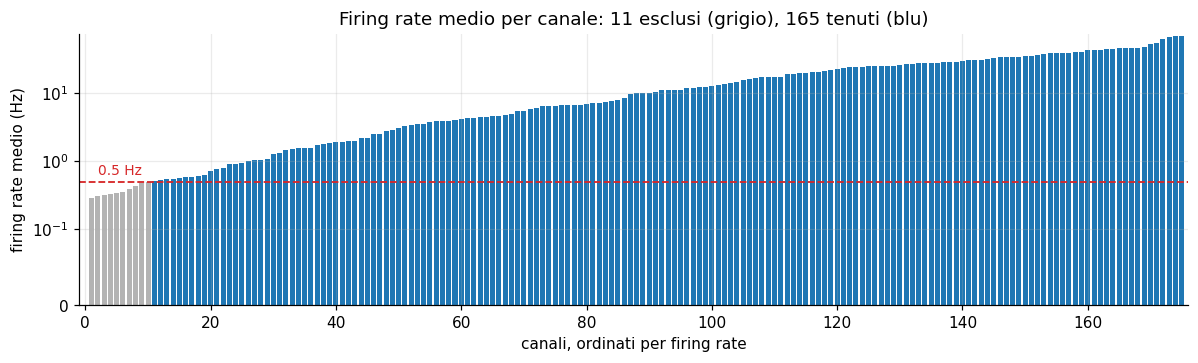

In [5]:
duration_s = n_bins * BIN_S                             # durata della sessione in secondi
rate_hz = counts.sum(axis=0) / duration_s               # firing rate medio di ogni canale = eventi totali / durata
MIN_HZ = 0.5                                            # soglia di attività (scelta nostra)
ACTIVE = np.flatnonzero(rate_hz >= MIN_HZ)              # indici dei canali che superano la soglia
X_counts = counts[:, ACTIVE]                            # matrice ridotta: solo le colonne dei canali attivi

print(f"Canali attivi: {len(ACTIVE)} su {n_ch}  (esclusi {n_ch - len(ACTIVE)})")
print("Stessa selezione di io.active_units:", np.array_equal(ACTIVE, io.active_units(s, min_hz=MIN_HZ)))
print(f"Canali con zero eventi in tutta la sessione: {(rate_hz == 0).sum()}")
display(pd.DataFrame({"soglia (Hz)": [0.1, 0.5, 1, 2, 5],
                      "canali esclusi": [int((rate_hz < th).sum()) for th in (0.1, 0.5, 1, 2, 5)]})
        .set_index("soglia (Hz)").T)

fig, ax = plt.subplots(figsize=(11, 3.4))
order = np.argsort(rate_hz)                             # canali ordinati dal meno al più attivo
ax.bar(np.arange(n_ch), rate_hz[order], width=0.8,
       color=np.where(rate_hz[order] >= MIN_HZ, "C0", "0.7"))  # blu = tenuti, grigio = esclusi
ax.axhline(MIN_HZ, color="C3", ls="--", lw=1.2)
ax.text(2, MIN_HZ * 1.25, f"{MIN_HZ} Hz", color="C3", fontsize=9)
ax.set_yscale("symlog", linthresh=0.1)                  # scala logaritmica che accetta anche lo zero: i canali lenti restano visibili
ax.set(xlabel="canali, ordinati per firing rate", ylabel="firing rate medio (Hz)",
       title=f"Firing rate medio per canale: {n_ch - len(ACTIVE)} esclusi (grigio), {len(ACTIVE)} tenuti (blu)",
       xlim=(-1, n_ch))
fig.tight_layout(); fig.savefig(FIGS / "02new_active_channels.png", bbox_inches="tight"); plt.show()

**Una nota per quando useremo più sessioni.** La selezione va fatta **una volta sola** (per
esempio sulle sessioni di training) e poi tenuta fissa. Se ogni sessione avesse il proprio insieme
di canali, lo spazio di partenza della PCA cambierebbe da una sessione all'altra e i manifold non
sarebbero confrontabili.

## 4 · Smoothing: da conteggi rumorosi a firing rate

### Perché serve

Guardiamo che cosa contiene davvero un bin da 20 ms.

In [6]:
vals, freq = np.unique(X_counts, return_counts=True)    # valori distinti presenti nella matrice e quante volte compaiono
frac = freq / X_counts.size                             # frazione di bin con 0, 1, 2, ... eventi
display(pd.DataFrame({"eventi nel bin": vals[:5], "frazione dei bin (%)": (frac[:5] * 100).round(2)})
        .set_index("eventi nel bin").T)
print(f"Media: {X_counts.mean():.2f} eventi per bin e per canale "
      f"(= {X_counts.mean() / BIN_S:.1f} Hz)")

eventi nel bin,0,1,2,3,4
frazione dei bin (%),74.2,19.45,5.06,1.08,0.18


Media: 0.34 eventi per bin e per canale (= 16.8 Hz)


Più di tre bin su quattro valgono 0 e quasi tutti gli altri valgono 1. Il canale medio scarica a
~14 Hz, cioè **0.28 eventi per bin**: in ogni singolo bin ne vediamo 0 oppure 1, in buona parte
per caso. Il singolo bin dà quindi una stima pessima del firing rate: dice "0 Hz" oppure
"50 Hz", mai 14 Hz.

Quello che ci interessa è il **firing rate sottostante** λ(t): una grandezza che varia
lentamente, su scale di centinaia di ms, seguendo il movimento. I conteggi ne sono campioni
rumorosi (approssimativamente di Poisson). Per stimare λ(t) in un istante facciamo una **media
pesata dei bin vicini**: è questo lo smoothing.

### Come lo facciamo

Usiamo un **kernel gaussiano** con deviazione standard σ = 50 ms (2.5 bin), cioè una media pesata
in cui il bin centrale pesa di più e il peso cala dolcemente allontanandosi.

- **Quanto rumore toglie.** Per un rumore indipendente da bin a bin, un kernel gaussiano equivale
  a mediare circa 2√π · σ ≈ 8.9 bin (circa 180 ms): la varianza del rumore si riduce di circa
  9 volte.
- **Che cosa costa.** Le variazioni più rapide di σ vengono attenuate. Le modulazioni della
  corteccia motoria legate al movimento durano centinaia di ms, quindi con σ = 50 ms restano.
- **Perché non usare semplicemente bin più larghi?** Perché perderemmo l'allineamento a 20 ms con
  la cinematica. Lo smoothing gaussiano riduce il rumore **mantenendo un valore ogni 20 ms**, e
  i suoi pesi calano gradualmente invece di tagliare di netto a un bordo.
- **Il kernel è simmetrico**: usa sia il passato sia il futuro, quindi non introduce ritardi. Va
  bene per l'analisi offline; un decoder online non ha il futuro e userebbe un filtro causale.

Il filtro agisce **lungo il tempo, canale per canale**: non mescola mai canali diversi. Per questo
l'ordine tra selezione (§3) e smoothing è indifferente. Lo applichiamo all'intera sessione di
seguito, attraversando i confini tra trial, perché la registrazione è continua.

In [7]:
SIGMA_MS = 50                                           # deviazione standard del kernel gaussiano, in ms
sigma_bins = (SIGMA_MS / 1000) / BIN_S                  # la stessa, espressa in bin: 0.050 s / 0.020 s = 2.5 bin
smoothed = gaussian_filter1d(X_counts.astype(float),    # conversione in float: dopo la media i valori non sono più interi
                             sigma=sigma_bins,          # larghezza del kernel, in bin
                             axis=0,                    # lungo il tempo (le righe): ogni canale è filtrato separatamente
                             mode="nearest")            # ai bordi della registrazione ripete il primo/ultimo valore
                                                        # invece di aggiungere zeri inesistenti
rates = smoothed / BIN_S                                # da "eventi per bin" a "eventi al secondo" (Hz): solo un cambio di unità

print(f"Firing rate: matrice {rates.shape[0]} × {rates.shape[1]}, sigma = {SIGMA_MS} ms = {sigma_bins} bin")
print(f"Finestra equivalente del kernel: {2 * np.sqrt(np.pi) * sigma_bins:.1f} bin "
      f"= {2 * np.sqrt(np.pi) * SIGMA_MS:.0f} ms")
print("Identico a io.smooth_rates:",
      np.allclose(rates, io.smooth_rates(counts, sigma_ms=SIGMA_MS)[:, ACTIVE], atol=1e-4))

Firing rate: matrice 12078 × 165, sigma = 50 ms = 2.5 bin
Finestra equivalente del kernel: 8.9 bin = 177 ms
Identico a io.smooth_rates: True


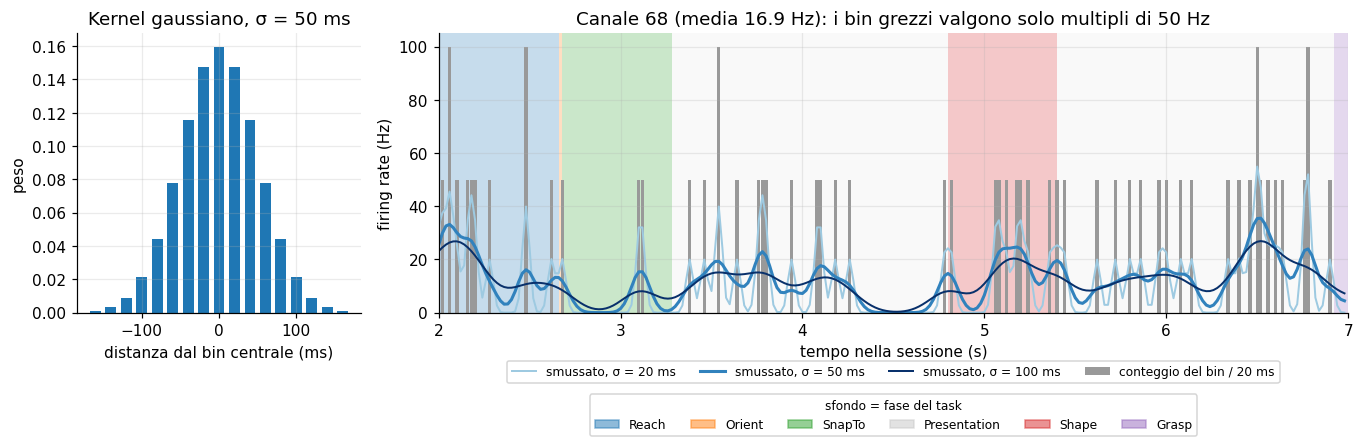

In [8]:
ch = int(np.argmin(np.abs(rate_hz[ACTIVE] - rate_hz[ACTIVE].mean())))  # un canale "tipico": quello con il firing rate più vicino alla media
a, b = io.trial_slices(s)[0]                            # bin di inizio e fine del primo trial
a, b = a + 100, a + 350                                 # ne prendiamo 5 s (250 bin), dal secondo 2 al secondo 7
t = np.arange(a, b) * BIN_S                             # asse dei tempi in secondi

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1, 3.2]})
k = np.arange(-8, 9)                                    # posizioni dei bin intorno al centro del kernel
w = np.exp(-0.5 * (k / sigma_bins) ** 2); w /= w.sum()  # pesi gaussiani, normalizzati a somma 1
ax[0].bar(k * BIN_S * 1000, w, width=14, color="C0")
ax[0].set(xlabel="distanza dal bin centrale (ms)", ylabel="peso",
          title=f"Kernel gaussiano, σ = {SIGMA_MS} ms")

# Sfondo colorato con le fasi del task (come al §7): serve a vedere se i picchi della curva
# cadono durante il movimento, cioè se lo smoothing tiene il segnale e non solo "pulisce" la curva
fase = lambda tag: "Presentation" if tag.startswith("Presentation") else tag  # "Presentation3" -> "Presentation"
ep = s.epochs[(s.epochs.stop_time > t[0]) & (s.epochs.start_time < t[-1] + BIN_S)]  # fasi che cadono nella finestra mostrata
for _, e in ep.iterrows():
    ax[1].axvspan(max(e.start_time, t[0]), min(e.stop_time, t[-1] + BIN_S),  # tagliata ai bordi della finestra
                  color=io.PHASE_COLORS.get(fase(e.tag), "0.9"), lw=0,
                  alpha=0.10 if fase(e.tag) in ("Presentation", "Intertrial") else 0.25)  # fasi di movimento più marcate

ax[1].bar(t, X_counts[a:b, ch] / BIN_S, width=BIN_S * 0.9, color="0.6", label="conteggio del bin / 20 ms")
for sig, c in [(20, "#9ecae1"), (50, "#3182bd"), (100, "#08306b")]:   # tre larghezze, dal chiaro (stretto) allo scuro (largo)
    r_ = gaussian_filter1d(X_counts[:, ch].astype(float), sig / 1000 / BIN_S, mode="nearest") / BIN_S
    ax[1].plot(t, r_[a:b], color=c, lw=2 if sig == SIGMA_MS else 1.3, label=f"smussato, σ = {sig} ms")
ax[1].set(xlabel="tempo nella sessione (s)", ylabel="firing rate (Hz)", xlim=(t[0], t[-1] + BIN_S),
          title=f"Canale {ACTIVE[ch]} (media {rate_hz[ACTIVE][ch]:.1f} Hz): i bin grezzi valgono solo multipli di 50 Hz")

leg = ax[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)  # legenda delle curve, sotto il grafico
ax[1].add_artist(leg)                                   # la teniamo, così possiamo aggiungere una seconda legenda
fasi_viste = list(dict.fromkeys(fase(x) for x in ep.tag))  # fasi presenti nella finestra, in ordine di comparsa
ax[1].legend(handles=[Patch(color=io.PHASE_COLORS.get(f, "0.9"), alpha=0.5, label=f) for f in fasi_viste],
             fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=len(fasi_viste), title="sfondo = fase del task",
             title_fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "02new_smoothing.png", bbox_inches="tight"); plt.show()

**Lettura.** Le barre grigie sono il conteggio grezzo: un bin con un evento "dice" 50 Hz, uno con
due eventi 100 Hz, uno vuoto 0 Hz. Le curve sono la stima del firing rate con tre larghezze di kernel. Con
**σ = 20 ms** la curva è ancora dominata dagli eventi singoli; con **σ = 100 ms** diventa molto
liscia ma appiattisce anche le variazioni vere. **σ = 50 ms** è il compromesso che adottiamo,
e quanto questa scelta pesi sul risultato della PCA lo misuriamo al §6.

**Lo sfondo colorato è la fase del task** (come al §7): serve a controllare che i picchi della
curva non siano solo rumore smussato. I due picchi più alti della curva a σ = 50 ms, a circa
2.76 s e 4.84 s, cadono durante `Reach` e `Orient`, due fasi di movimento; in questo tratto il
canale scarica in media a circa 20 Hz durante il movimento e a circa 11 Hz durante le
`Presentation`. Lo smoothing lascia quindi passare variazioni legate al task.

Attenzione a non chiedere troppo a questa figura: è **un canale in un trial**, un'illustrazione e
non una prova. La verifica vera, su tutta la popolazione e su tutte le ripetizioni, è ai §7 e §8.

La divisione per 0.02 s trasforma i conteggi in Hz, ma è **solo un cambio di unità**: dopo lo
z-score del §5 sparisce (moltiplicare una colonna per una costante non cambia il suo z-score).
Serve solo a rendere leggibili le figure.

## 5 · Normalizzazione (z-score) per canale

### Perché serve

La PCA cerca le direzioni di **varianza massima**. Nei dati di conteggio, però, la varianza
cresce con la media (per un processo di Poisson sono uguali). Un canale che scarica a 50 Hz ha
molta più varianza di uno a 5 Hz **solo perché scarica di più**, non perché porti più
informazione. Senza normalizzare, la prima componente finirebbe per descrivere soprattutto i
pochi canali più attivi.

Lo **z-score** trasforma ogni canale così: z = (x − media) / deviazione standard. Fa due cose:

1. **sottrae la media** (centratura). La PCA la richiede comunque: cerca le direzioni di
   variazione *intorno alla media*;
2. **divide per la deviazione standard**, così ogni canale ha varianza 1 e conta allo stesso modo.
   La PCA opera allora sulla matrice di **correlazione** tra canali, invece che su quella di
   covarianza.

Qui sotto verifichiamo le due affermazioni: varianza legata alla media, e PC1 dominata dai canali
più attivi se non si normalizza.

Correlazione tra media e varianza dei canali: r = 0.92
Dopo lo z-score: medie in [-1.8e-14, 3.0e-14], deviazioni standard in [1.000, 1.000]
Peso dei 10 canali più attivi nella PC1 (somma dei pesi al quadrato, su un totale di 1): 0.24 senza z-score, 0.08 con z-score


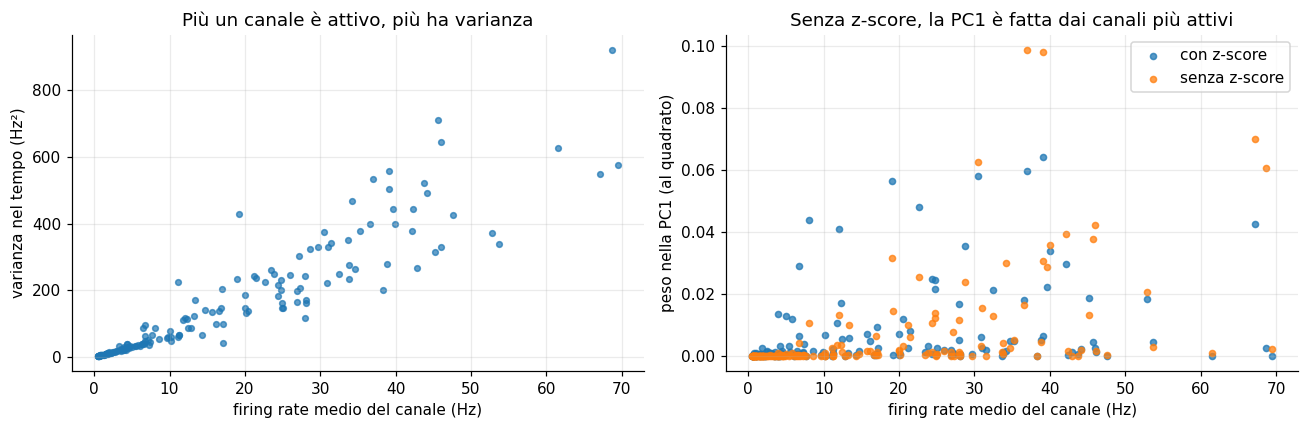

In [9]:
mu = rates.mean(axis=0)                                 # media temporale di ogni canale (Hz)
var = rates.var(axis=0)                                 # varianza temporale di ogni canale
print(f"Correlazione tra media e varianza dei canali: r = {np.corrcoef(mu, var)[0, 1]:.2f}")

Z = StandardScaler().fit_transform(rates)               # per ogni colonna: sottrae la media e divide per la deviazione standard
print(f"Dopo lo z-score: medie in [{Z.mean(0).min():.1e}, {Z.mean(0).max():.1e}], "
      f"deviazioni standard in [{Z.std(0).min():.3f}, {Z.std(0).max():.3f}]")

pc1_raw = PCA(n_components=1).fit(rates).components_[0]  # PC1 senza normalizzare (sklearn centra comunque i dati)
pc1_z = PCA(n_components=1).fit(Z).components_[0]        # PC1 dopo lo z-score
top10 = np.argsort(mu)[::-1][:10]                        # i 10 canali con firing rate più alto
print(f"Peso dei 10 canali più attivi nella PC1 (somma dei pesi al quadrato, su un totale di 1): "
      f"{(pc1_raw[top10] ** 2).sum():.2f} senza z-score, {(pc1_z[top10] ** 2).sum():.2f} con z-score")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(mu, var, s=14, color="C0", alpha=0.7)
ax[0].set(xlabel="firing rate medio del canale (Hz)", ylabel="varianza nel tempo (Hz²)",
          title="Più un canale è attivo, più ha varianza")
ax[1].scatter(mu, pc1_z ** 2, s=16, color="C0", alpha=0.75, label="con z-score")
ax[1].scatter(mu, pc1_raw ** 2, s=16, color="C1", alpha=0.75, label="senza z-score")  # disegnati per ultimi, per non restare coperti
ax[1].set(xlabel="firing rate medio del canale (Hz)", ylabel="peso nella PC1 (al quadrato)",
          title="Senza z-score, la PC1 è fatta dai canali più attivi")
ax[1].legend()
fig.tight_layout(); fig.savefig(FIGS / "02new_normalization.png", bbox_inches="tight"); plt.show()

### Il legame con la selezione dei canali (§3)

Lo z-score ha un costo: dà a ogni canale lo stesso peso, **compresi quelli quasi silenti**, che
hanno pochissimo segnale. Se non li avessimo tolti, lo z-score li avrebbe amplificati. Lo
verifichiamo ripetendo smoothing e z-score su **tutti** i 176 canali e guardando il valore più
estremo che ogni canale raggiunge.

In [10]:
rates_all = gaussian_filter1d(counts.astype(float), sigma_bins, axis=0, mode="nearest") / BIN_S  # smoothing di tutti i 176 canali
sd_all = rates_all.std(axis=0)                          # deviazione standard di ciascun canale
silent = (rate_hz < MIN_HZ) & (sd_all > 0)              # canali esclusi che però hanno almeno un evento
z_peak = (rates_all.max(0) - rates_all.mean(0)) / np.where(sd_all > 0, sd_all, np.nan)  # picco z-score per canale
print(f"Canali con varianza zero (z-score impossibile): {(sd_all == 0).sum()}")
print(f"Picco dello z-score, mediana: {np.nanmedian(z_peak[silent]):.1f} nei canali quasi silenti, "
      f"{np.median(z_peak[ACTIVE]):.1f} nei canali attivi")

Canali con varianza zero (z-score impossibile): 1
Picco dello z-score, mediana: 10.4 nei canali quasi silenti, 5.8 nei canali attivi


Nei canali quasi silenti i rari eventi producono picchi di z-score più alti che nei canali attivi
(mediana 9.8 contro 6.3): pochi punti isolati, lontani dalla media, il tipo di punto che la PCA
tende a inseguire. Un canale, poi, non si può proprio normalizzare. Selezione dei canali e
z-score vanno quindi insieme.

**Alternativa.** La *soft normalization* di Churchland et al. (2012) divide per (escursione del
canale + 5 Hz): una via di mezzo che riduce il peso dei canali molto attivi senza amplificare
quelli deboli. Teniamo lo z-score per coerenza con il notebook 02.

## 6 · PCA

### Cosa calcola

Chiamiamo **Z** la matrice T × N dei dati normalizzati (T = bin, N = 160 canali).

1. **Matrice di covarianza** tra canali: C = Zᵀ Z / (T − 1), di dimensione N × N. L'elemento
   C[i, j] dice quanto i canali i e j variano insieme. Siccome Z è z-scored, C è la matrice di
   correlazione.
2. **Autovettori e autovalori** di C: C = W Λ Wᵀ.
   - Ogni colonna di **W** è una **direzione principale**: una combinazione dei 160 canali, cioè
     un "modo" di co-attivazione della popolazione.
   - Ogni autovalore λₖ è la **varianza** dei dati lungo quella direzione. Le componenti sono
     ordinate da quella con varianza maggiore alla minore, e sono ortogonali tra loro.
3. **Proiezione**: Y = Z W. La riga t di Y dice dove si trova la popolazione, all'istante t,
   lungo ciascuna direzione. Le prime colonne di Y sono la **traiettoria latente**.

Da λ ricaviamo le misure di dimensionalità:

- **varianza spiegata** dalla componente k: λₖ / Σλ;
- **participation ratio**: PR = (Σλ)² / Σλ². Vale 1 se tutta la varianza sta in una direzione e
  N se è distribuita in modo uniforme su tutte: è un "numero efficace di dimensioni".

In [11]:
pca = PCA()                                             # senza n_components: calcola tutte le 160 componenti (spettro completo)
scores = pca.fit_transform(Z)                           # fit = stima le direzioni; transform = proietta ogni bin -> matrice T × 160
W = pca.components_.T                                   # direzioni principali: una colonna per componente, 160 pesi ciascuna
lam = pca.explained_variance_                           # varianza lungo ogni direzione (gli autovalori), in ordine decrescente
evr = pca.explained_variance_ratio_                     # la stessa varianza, come frazione del totale
cum = np.cumsum(evr)                                    # varianza cumulativa delle prime k componenti

print(f"Scores: {scores.shape}   Direzioni W: {W.shape}")
print(f"Somma degli autovalori = {lam.sum():.1f}  (= numero di canali: dopo lo z-score ognuno porta varianza 1)")

Scores: (12078, 165)   Direzioni W: (165, 165)
Somma degli autovalori = 165.0  (= numero di canali: dopo lo z-score ognuno porta varianza 1)


**Controllo: la PCA di scikit-learn è davvero questa algebra.** Rifacciamo il calcolo a mano con
`numpy` e confrontiamo i risultati.

In [12]:
C = np.cov(Z, rowvar=False)                             # covarianza 160 × 160 tra le colonne (i canali) di Z
eigval, eigvec = np.linalg.eigh(C)                      # autovalori e autovettori di una matrice simmetrica (in ordine crescente)
order_ = np.argsort(eigval)[::-1]                       # indici per metterli in ordine decrescente
eigval, eigvec = eigval[order_], eigvec[:, order_]      # riordino: prima la direzione con varianza massima
Y = Z @ eigvec[:, :3]                                   # proiezione a mano sulle prime 3 direzioni

print("Autovalori identici a pca.explained_variance_:", np.allclose(eigval, lam))
print("Correlazione (in valore assoluto) tra proiezione a mano e scores di sklearn, PC1-3:",
      [round(abs(np.corrcoef(Y[:, k], scores[:, k])[0, 1]), 6) for k in range(3)])

Autovalori identici a pca.explained_variance_: True
Correlazione (in valore assoluto) tra proiezione a mano e scores di sklearn, PC1-3: [np.float64(1.0), np.float64(1.0), np.float64(1.0)]


Coincidono. La correlazione è in valore assoluto perché un autovettore è definito **a meno del
segno**: w e −w descrivono la stessa direzione. L'asse di una PC può quindi uscire "capovolto" da
un calcolo all'altro, e il segno delle PC non va interpretato.

### Quante dimensioni?

Participation ratio: 94.4
PC1: 4.8%   PC1-3: 11.0%   componenti per l'80%: 100   per il 90%: 126   (su 165)


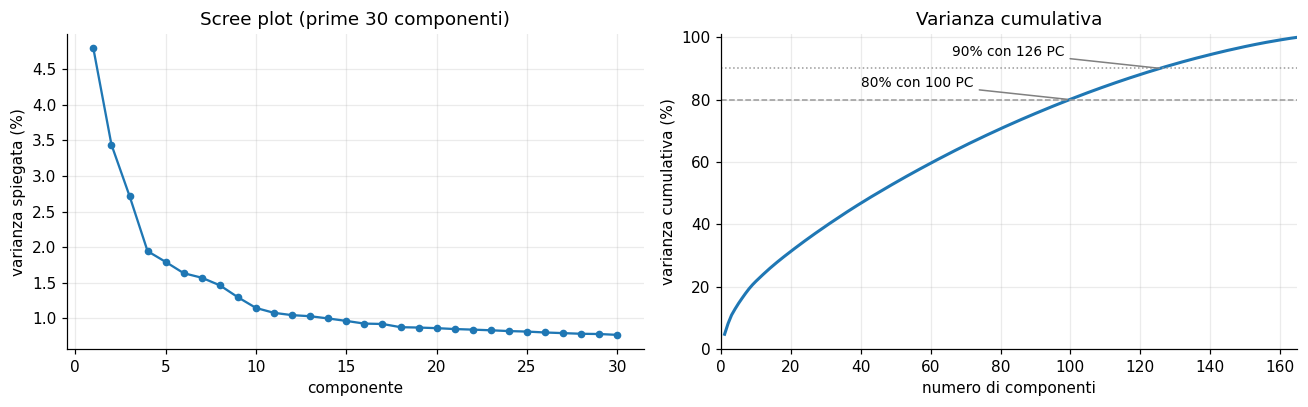

In [13]:
PR = lam.sum() ** 2 / (lam ** 2).sum()                  # participation ratio
n80 = int(np.searchsorted(cum, 0.80) + 1)               # prima k con varianza cumulativa >= 80%
n90 = int(np.searchsorted(cum, 0.90) + 1)               # prima k con varianza cumulativa >= 90%
print(f"Participation ratio: {PR:.1f}")
print(f"PC1: {evr[0] * 100:.1f}%   PC1-3: {cum[2] * 100:.1f}%   "
      f"componenti per l'80%: {n80}   per il 90%: {n90}   (su {Z.shape[1]})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.arange(1, 31), evr[:30] * 100, "o-", color="C0", ms=4, lw=1.5)
ax[0].set(xlabel="componente", ylabel="varianza spiegata (%)", title="Scree plot (prime 30 componenti)")
ax[1].plot(np.arange(1, len(cum) + 1), cum * 100, color="C0", lw=2)
for q, n, ls in [(80, n80, "--"), (90, n90, ":")]:
    ax[1].axhline(q, color="0.6", ls=ls, lw=1)
    ax[1].annotate(f"{q}% con {n} PC", (n, q), xytext=(n - 60, q + 4), fontsize=9,
                   arrowprops=dict(arrowstyle="-", color="0.5"))
ax[1].set(xlabel="numero di componenti", ylabel="varianza cumulativa (%)",
          title="Varianza cumulativa", ylim=(0, 101), xlim=(0, Z.shape[1]))
fig.tight_layout(); fig.savefig(FIGS / "02new_pca_scree.png", bbox_inches="tight"); plt.show()

**Lettura.** La varianza è **distribuita su moltissime direzioni**: le prime 3 componenti ne
spiegano meno del 9% e ne servono circa 100 su 160 per arrivare all'80%. Il participation ratio
(~106) è lo stesso del notebook 02.

Non vuol dire che l'attività motoria sia a 100 dimensioni. A 20 ms, con 0.28 eventi per bin,
ogni canale è dominato dal **rumore di Poisson**, che è indipendente tra canali e quindi si
spalma in modo uniforme su tutte le direzioni. La PCA massimizza la varianza *totale* e non sa
distinguere questo rumore dal segnale condiviso. Resta comunque un segnale: le prime componenti
spiegano più della media (1/160 ≈ 0.6% ciascuna).

In [14]:
# REPLICA: solo le definizioni della cella tolta 30
def pr(v):                                              # participation ratio; non cambia se le varianze sono in frazioni
    return v.sum() ** 2 / (v ** 2).sum()

**Lettura.**

- Il participation ratio **cala in modo continuo** all'aumentare di σ: da ~150 sui conteggi
  grezzi a ~65 con σ = 200 ms, meno della metà. Lo smoothing toglie rumore indipendente tra
  canali e lascia emergere la parte comune. σ = 10 ms dà quasi lo stesso risultato dei conteggi
  grezzi: è mezzo bin, e il kernel mescola pochissimo i bin vicini.
- **Non c'è un plateau**, cioè nessun valore di σ oltre il quale la dimensionalità smette di
  cambiare e si possa dire "questa è la dimensionalità vera". Il PR quindi **non serve a scegliere
  σ**. σ = 50 ms si sceglie per un altro motivo: la scala temporale del segnale (le modulazioni
  motorie durano centinaia di ms, §4). Un criterio basato sul comportamento, cioè quanto bene le
  componenti predicono la cinematica al variare di σ, arriverà con il decoder.
- **La conclusione qualitativa invece regge**: con qualunque σ servono molte decine di componenti
  per arrivare all'80% della varianza. Che l'attività single-trial sia ad alta dimensione e dominata
  dal rumore non dipende da σ; il numero esatto sì.

Per questo nel notebook 02 si passava a FA e GPFA, che separano segnale e rumore con un modello
statistico invece che con un filtro scelto da noi.

> **Regola per la tesi.** Un numero di dimensionalità ottenuto con la PCA va sempre riportato
> insieme al preprocessing che lo ha prodotto, per esempio: *"PR ≈ 106 (bin 20 ms, smoothing
> gaussiano σ = 50 ms, z-score, 160 canali, una sessione)"*. Senza σ il numero non è
> confrontabile con nessun altro.

## 7 · Che cosa si vede nelle prime componenti

Proiettiamo un trial sulle prime 3 PC e coloriamo lo sfondo con le fasi del task. Teniamo tutti i
bin, comprese le `Presentation` e gli `Intertrial`: `eval_mask` riguarda la cinematica ("Neural
data is not affected", dice il file), mentre qui stiamo analizzando solo l'attività neurale.

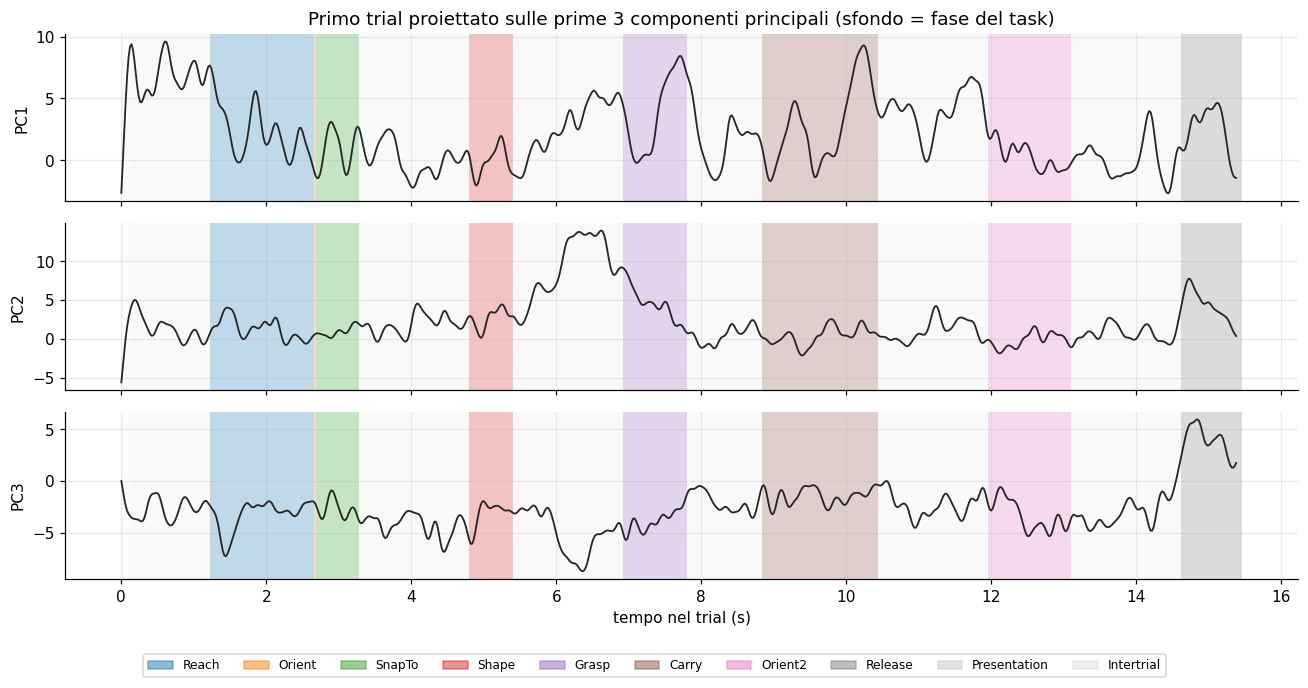

In [15]:
def base_tag(tag):                                      # "Presentation3" -> "Presentation": un solo colore per tutte le presentazioni
    return "Presentation" if tag.startswith("Presentation") else tag

a, b = io.trial_slices(s)[0]                            # bin di inizio e fine del primo trial
t = np.arange(a, b) * BIN_S                             # tempo di ogni bin del trial, in secondi
ep = s.epochs[(s.epochs.stop_time > t[0]) & (s.epochs.start_time < t[-1])]  # fasi che cadono nel trial

fig, ax = plt.subplots(3, 1, figsize=(12, 6.2), sharex=True)
for k in range(3):                                      # un pannello per componente
    for _, e in ep.iterrows():                          # sfondo colorato con la fase
        ax[k].axvspan(e.start_time, e.stop_time, color=io.PHASE_COLORS[base_tag(e.tag)],
                      alpha=0.10 if base_tag(e.tag) in ("Presentation", "Intertrial") else 0.28, lw=0)
    ax[k].plot(t, scores[a:b, k], color="0.15", lw=1.2)  # la traiettoria sulla PC k
    ax[k].set_ylabel(f"PC{k + 1}")
ax[-1].set_xlabel("tempo nel trial (s)")
ax[0].set_title("Primo trial proiettato sulle prime 3 componenti principali (sfondo = fase del task)")
handles = [Patch(color=io.PHASE_COLORS[p], alpha=0.5, label=p) for p in io.MOVEMENT_PHASES + ("Presentation", "Intertrial")]
fig.legend(handles=handles, ncol=10, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(FIGS / "02new_pca_timecourse.png", bbox_inches="tight"); plt.show()

**Lettura.** Alcune variazioni seguono le fasi: PC3 ha un'escursione netta durante `Orient` e
`Grasp`, PC2 durante `Carry` e `Orient2`. Sopra c'è però molto rumore bin per bin, controparte
visiva del participation ratio ~106, e da un solo trial non si può dire quanto queste
escursioni si ripetano da un trial all'altro. Con le fasi del task come condizioni
ripetute si può fare di meglio mediando le ripetizioni (PSTH) o usando un modello del rumore (FA)
e del tempo (GPFA). Sono i passi successivi.

## 8 · Il segnale c'è? PCA sulle medie per condizione

Al §6 la PCA ha trovato ~106 dimensioni, e abbiamo detto che sono soprattutto rumore. Qui lo
verifichiamo.

**L'idea.** In ogni trial il partecipante ripete la stessa sequenza di fasi, quindi in una
sessione ogni fase si ripete circa 15 volte. Ogni ripetizione contiene:

- il **segnale**, cioè quello che il cervello fa per quel movimento: è (quasi) uguale ogni volta;
- il **rumore**, che invece è diverso ogni volta.

Se facciamo la **media delle ripetizioni**, il rumore si cancella e il segnale resta, come quando
si sovrappongono 15 foto sgranate della stessa scena. Poi facciamo la PCA sulle medie.

Per ogni fase di movimento prendiamo la finestra di **1 s che parte dall'inizio della fase**
(50 bin). Usiamo i dati del §5 (smussati a σ = 50 ms e z-scored), così il confronto con il §6 è
diretto.

**Perché 1 s.** La finestra ha una durata fissa, uguale per tutte le fasi e tutte le ripetizioni,
per due motivi:

1. **Deve contenere tutta la risposta neurale.** Nel notebook 01 (§7, PSTH di popolazione
   allineato all'inizio delle fasi) la risposta delle fasi più modulate, quelle della mano, sale
   subito, ha il picco a circa 250 ms e torna verso la base a circa 0.7-0.8 s (`Shape`,
   `Release`; `Grasp` resta alta fino a circa 0.6-0.7 s). Una finestra da 1 s la contiene per
   intero; una da 0.5 s ne taglierebbe la seconda metà.
2. **Per fare la media delle ripetizioni, le finestre devono avere la stessa lunghezza** (tutte
   50 bin). Questo spiega perché la durata è fissa, non perché valga 1 s.

**Cosa contiene la finestra oltre alla fase.** Metà delle fasi dura meno di 1 s (`SnapTo` circa
0.4 s, `Shape` 0.6 s, `Grasp` e `Release` 0.8 s), l'altra metà di più (`Reach`, `Orient`, `Carry`,
`Orient2`, 1.1-1.5 s). Dopo ogni movimento viene sempre una `Presentation`, cioè il cue del
movimento successivo con il braccio fermo: la finestra di una fase breve sconfina in quel cue, non
nel movimento dopo. Siccome la sequenza delle fasi è sempre la stessa, anche il pezzo in più è lo
stesso in ogni ripetizione.

1 s resta comunque una scelta nostra: al §10.7 rifacciamo le misure principali con finestre da
0.5 e 0.75 s, e anche senza le ripetizioni in cui la fase dura un solo bin.

**Le condizioni sono 16, non 8: fase × versione del task.** Il task alterna due versioni tra
trial dispari e trial pari (lo abbiamo scoperto nel notebook 03, §9.2): per esempio il grado di
libertà g3 della presa va in direzioni opposte, in `Shape` scende nei trial dispari e sale nei
pari. Le circa 15 ripetizioni di una fase **non sono quindi repliche dello stesso movimento**:
sono circa 7-8 ripetizioni di una versione e 7-8 dell'altra. Mediarle tutte insieme mescola due
risposte diverse. Per questo una **condizione** è una coppia (fase, versione), con la versione data
dal numero del trial in cui la finestra comincia (dispari o pari): 8 fasi × 2 versioni = 16
condizioni, con circa 7 ripetizioni ciascuna.

In [16]:
WIN_S = 1.0                                             # durata della finestra dopo l'inizio di ogni fase, in s
L = int(round(WIN_S / BIN_S))                           # la stessa durata in bin: 1 s / 20 ms = 50
windows = io.phase_windows(s, win_s=WIN_S, align="start")  # una finestra per ogni ripetizione di ogni fase di movimento
VERSIONS = ("dispari", "pari")                          # le due versioni del task: trial dispari e trial pari

def cond_of(w):                                         # la condizione di una finestra: (fase, versione)
    return (w["tag"], "dispari" if w["trial"] % 2 == 1 else "pari")

CONDS = [(ph, v) for ph in io.MOVEMENT_PHASES for v in VERSIONS]  # le 16 condizioni, fase per fase
reps = {c: np.stack([Z[w["start"]:w["stop"]]            # per ogni condizione, le sue finestre una sopra l'altra:
                     for w in windows if cond_of(w) == c])  # array (ripetizioni, 50 bin, 160 canali)
        for c in CONDS}
print("Ripetizioni per condizione:", {f"{ph} {v}": r.shape[0] for (ph, v), r in reps.items()})

PSTH = np.concatenate([reps[c].mean(axis=0)             # media sulle ripetizioni (asse 0): una finestra "media" per condizione
                       for c in CONDS])                 # le 16 condizioni una dopo l'altra: matrice (16 × 50, 160) = (800, 160)
pca_avg = PCA().fit(PSTH)                               # PCA sulle medie
lam_avg = pca_avg.explained_variance_                   # le varianze lungo le sue direzioni
print(f"PCA sulle medie per condizione: matrice {PSTH.shape[0]} × {PSTH.shape[1]}, "
      f"participation ratio = {pr(lam_avg):.1f}, PC1-3 = {lam_avg[:3].sum() / lam_avg.sum() * 100:.0f}% della varianza")

Ripetizioni per condizione: {'Reach dispari': 8, 'Reach pari': 7, 'Orient dispari': 8, 'Orient pari': 7, 'SnapTo dispari': 8, 'SnapTo pari': 7, 'Shape dispari': 8, 'Shape pari': 7, 'Grasp dispari': 8, 'Grasp pari': 7, 'Carry dispari': 8, 'Carry pari': 7, 'Orient2 dispari': 8, 'Orient2 pari': 7, 'Release dispari': 7, 'Release pari': 7}
PCA sulle medie per condizione: matrice 800 × 165, participation ratio = 21.6, PC1-3 = 29% della varianza


### Attenzione: il confronto giusto non è 106 contro 11

Le due PCA non hanno lo stesso numero di punti: al §6 c'erano 12233 bin, qui 800 (16 condizioni ×
50 bin). Con pochi punti la PCA non riesce a "riempire" tante dimensioni, e il participation ratio
scende anche senza fare nessuna media. Per separare i due effetti teniamo **sempre 800 punti** e
cambiamo solo **quante ripetizioni mediamo**:

- **finestre allineate alle fasi**: per ogni condizione, la media di *n* ripetizioni scelte a caso;
- **controllo con finestre casuali**: stessa procedura, ma con finestre prese in punti a caso della
  sessione, non allineate a nessuna fase. Qui non c'è nessun segnale comune da far emergere.

Ogni estrazione casuale si ripete 20 volte e si fa la media dei risultati.

In [17]:
rng = np.random.default_rng(0)                          # seme fisso: le estrazioni casuali sono riproducibili
N_REP = min(r.shape[0] for r in reps.values())          # ripetizioni disponibili in tutte le condizioni (quella con meno)
N_DRAWS = 20                                            # quante estrazioni casuali per ogni valore di n
N_LIST = sorted({1, 2, 4, N_REP})                       # quante ripetizioni mediare

def pr_aligned(n):                                      # PR medio quando mediamo n ripetizioni vere di ogni condizione
    out = []
    for _ in range(N_DRAWS):
        M = np.concatenate([reps[c][rng.choice(len(reps[c]), n, replace=False)].mean(axis=0)  # n ripetizioni a caso, mediate
                            for c in CONDS])                                                 # le 16 condizioni in fila: (800, 160)
        out.append(pr(PCA().fit(M).explained_variance_))
    return np.mean(out)

def pr_random(n):                                       # stessa cosa, ma con finestre prese in punti a caso della sessione
    out = []
    for _ in range(N_DRAWS):
        M = np.concatenate([np.mean([Z[a:a + L] for a in rng.integers(0, n_bins - L, n)], axis=0)  # n finestre a caso, mediate
                            for _ in CONDS])                                                       # 16 "condizioni finte": (800, 160)
        out.append(pr(PCA().fit(M).explained_variance_))
    return np.mean(out)

pr_al = [pr_aligned(n) for n in N_LIST]                 # un PR per ogni n, finestre allineate
pr_rd = [pr_random(n) for n in N_LIST]                  # un PR per ogni n, finestre casuali
display(pd.DataFrame({"finestre allineate alle fasi": pr_al, "finestre casuali (controllo)": pr_rd},
                     index=pd.Index(N_LIST, name="ripetizioni mediate")).round(1).T)

ripetizioni mediate,1,2,4,7
finestre allineate alle fasi,48.5,43.1,32.9,22.6
finestre casuali (controllo),47.6,47.7,49.0,48.7


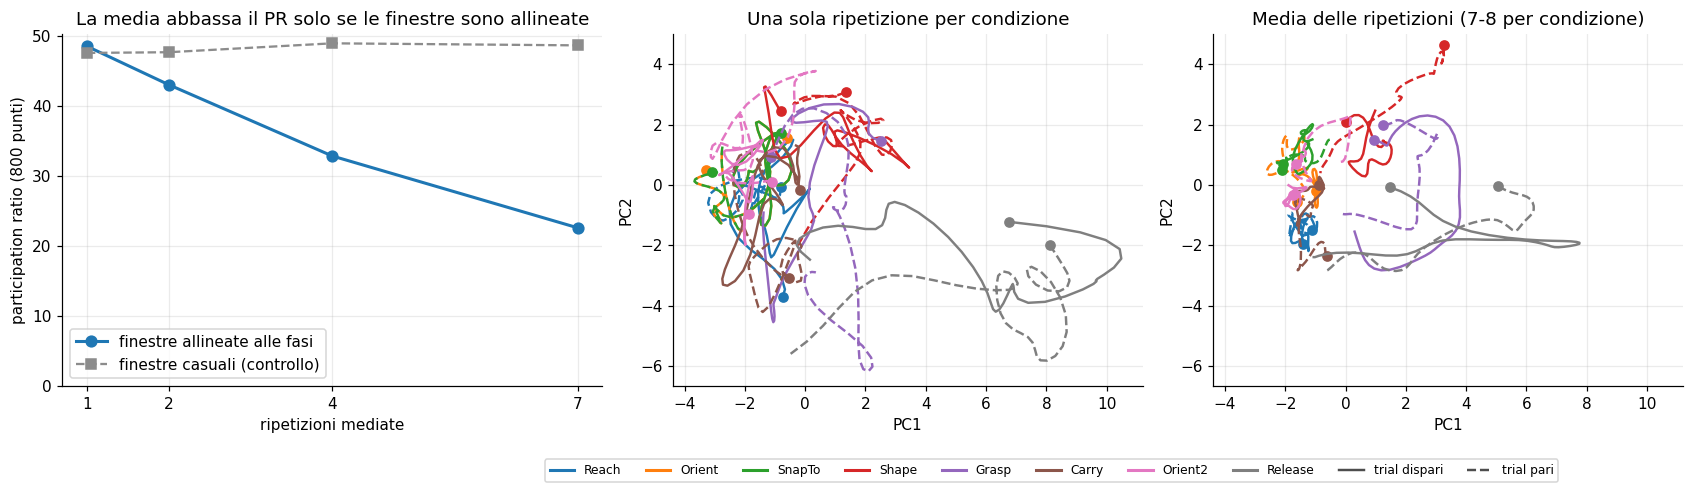

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.4), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax[0].plot(N_LIST, pr_al, "o-", color="C0", lw=2, ms=7, label="finestre allineate alle fasi")
ax[0].plot(N_LIST, pr_rd, "s--", color="0.55", lw=1.5, ms=7, label="finestre casuali (controllo)")
ax[0].set(xlabel="ripetizioni mediate", ylabel="participation ratio (800 punti)", xticks=N_LIST, ylim=(0, None),
          title="La media abbassa il PR solo se le finestre sono allineate")
ax[0].legend(loc="lower left")

VER_LS = {"dispari": "-", "pari": "--"}                 # linea continua = trial dispari, tratteggiata = trial pari
one = {c: pca_avg.transform(reps[c][0])[:, :2] for c in CONDS}        # la prima ripetizione di ogni condizione
avg = {c: pca_avg.transform(reps[c].mean(axis=0))[:, :2] for c in CONDS}  # la media di ogni condizione
for k, (D, ttl) in enumerate([(one, "Una sola ripetizione per condizione"),
                              (avg, f"Media delle ripetizioni ({N_REP}-{max(len(r) for r in reps.values())} per condizione)")], start=1):
    for (ph, v) in CONDS:
        ax[k].plot(D[(ph, v)][:, 0], D[(ph, v)][:, 1], color=io.PHASE_COLORS[ph], ls=VER_LS[v], lw=1.6)  # traiettoria nel piano PC1-PC2
        ax[k].plot(D[(ph, v)][0, 0], D[(ph, v)][0, 1], "o", color=io.PHASE_COLORS[ph], ms=6)  # pallino = inizio della fase
    ax[k].set(xlabel="PC1", ylabel="PC2", title=ttl)
lims = np.array([[*ax[k].get_xlim(), *ax[k].get_ylim()] for k in (1, 2)])  # i limiti che ciascun pannello sceglierebbe da solo
for k in (1, 2):                                        # stessa scala nei due pannelli, larga abbastanza per tutte le traiettorie
    ax[k].set_xlim(lims[:, 0].min(), lims[:, 1].max()); ax[k].set_ylim(lims[:, 2].min(), lims[:, 3].max())
handles = ([plt.Line2D([], [], color=io.PHASE_COLORS[ph], lw=2, label=ph) for ph in io.MOVEMENT_PHASES]
           + [plt.Line2D([], [], color="0.3", ls=VER_LS[v], lw=1.6, label=f"trial {v}") for v in VERSIONS])
fig.legend(handles=handles, ncol=10, fontsize=8, loc="lower center", bbox_to_anchor=(0.62, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIGS / "02new_pca_phase_averages.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **A parità di punti** (800), una sola ripetizione per condizione dà un participation ratio di
  circa 50. Mediando le 7 ripetizioni **allineate** disponibili in ogni condizione scende a circa
  21, e la curva non si è ancora fermata: con più ripetizioni scenderebbe ancora. ~20 è quindi un
  tetto, non il valore finale.
- Con le **finestre casuali** il PR resta intorno a 50 qualunque sia n. Mediare rumore puro dà
  ancora rumore, solo più piccolo, sparso sulle stesse direzioni. Il calo delle finestre allineate
  viene quindi da quello che le ripetizioni **hanno in comune**: il segnale del task.
- **Perché ~20 e non ~11, come mescolando le due versioni.** Con 8 condizioni (le fasi, senza
  distinguere la versione) si mediavano 14-15 ripetizioni su 400 punti; con 16 condizioni se ne
  mediano 7-8 su 800 punti. Meno ripetizioni lasciano più rumore, e più punti lasciano alla PCA
  più spazio per contarlo. Il numero più alto non vuol dire che il segnale sia più complesso: è
  il prezzo di non mescolare due movimenti diversi. Il calo con la media è circa il 59% (§10.7).
- Nelle figure: una ripetizione singola dà traiettorie aggrovigliate e sovrapposte; le medie danno
  traiettorie lisce e separate per condizione (linea continua = trial dispari, tratteggiata =
  trial pari). (Gli assi sono quelli della PCA sulle medie: vanno bene per guardare, non per
  misurare quanto è buona una traiettoria singola, perché quella PCA ha già "visto" le condizioni.)

**Il segnale c'è ed è semplice, ma nel singolo trial è sepolto nel rumore.** La media però in
pratica non si può fare: un'interfaccia cervello-computer deve capire il movimento **mentre** la
persona lo tenta, una volta sola. Serve un metodo che separi segnale e rumore **senza fare la
media**. È il compito della Factor Analysis.

## 9 · Factor Analysis: separare il segnale condiviso dal rumore di ogni canale

### L'idea

La FA descrive ogni canale come la somma di due parti:

- una **parte condivisa**: una combinazione di pochi *fattori* comuni a tutta la popolazione. È il
  segnale che ci interessa;
- una **parte privata**: il rumore del singolo canale, con un'ampiezza diversa da canale a canale.

Come in un coro: la FA separa la melodia che cantano tutti insieme dalle stonature di ciascun
cantante.

In formule, per ogni bin t:

$$x(t) = W\,z(t) + \mu + \varepsilon(t), \qquad \varepsilon(t) \sim \mathcal{N}(0, \Psi)$$

- $x(t)$: i 160 canali; $z(t)$: i K fattori condivisi, con K molto più piccolo di 160;
- $W$ (160 × K): quanto ogni canale "ascolta" ciascun fattore; $\mu$: la media di ogni canale;
- $\varepsilon(t)$: il rumore privato. $\Psi$ è diagonale: **una varianza di rumore diversa per
  ogni canale**, e nessun rumore in comune tra canali.

**La differenza con la PCA sta tutta in Ψ.** La PCA mette tutta la varianza nello stesso
calderone. La FA stima per ogni canale quanta della sua varianza è rumore privato e la mette da
parte: quello che resta, $W W^\top$, è la struttura condivisa.

### Tre scelte, e perché

1. **Conteggi grezzi a 20 ms, senza smoothing.** Il compito della FA è separare il rumore dal
   segnale: se smussiamo prima, togliamo noi una parte del rumore con un filtro scelto a mano e la
   FA non lo vede. Anche GPFA, il passo successivo, lavora sui conteggi grezzi. L'effetto dello
   smoothing lo misuriamo comunque al §9.5.
2. **Lo z-score qui non è necessario.** La FA stima un rumore diverso per ogni canale, quindi si
   adatta da sola alla scala di ciascuno. Lo applichiamo solo per comodità numerica, e al §9.2
   verifichiamo che i risultati non cambiano.
3. **Il numero di fattori K si sceglie con la cross-validation** (§9.1).

> **Nota tecnica.** La FA di scikit-learn, con le impostazioni di default, usa una SVD
> *approssimata*: su questi dati si ferma dopo pochissime iterazioni, prima di arrivare alla
> soluzione. Usiamo `svd_method="lapack"` (SVD esatta), che converge davvero. Lo verifichiamo qui
> sotto con un K qualunque (20), solo per il confronto.

In [19]:
X_fa = StandardScaler().fit_transform(X_counts.astype(float))  # conteggi grezzi dei 160 canali attivi, z-scored

fa_default = FactorAnalysis(n_components=20, random_state=0).fit(X_fa)                      # impostazioni di default
fa_exact = FactorAnalysis(n_components=20, svd_method="lapack", random_state=0).fit(X_fa)   # SVD esatta
print(f"default : {fa_default.n_iter_:3d} iterazioni, log-likelihood media = {fa_default.score(X_fa):.3f}")
print(f"esatta  : {fa_exact.n_iter_:3d} iterazioni, log-likelihood media = {fa_exact.score(X_fa):.3f}")

default :   4 iterazioni, log-likelihood media = -232.774
esatta  :  42 iterazioni, log-likelihood media = -232.531


In [20]:
# REPLICA: solo le definizioni della cella tolta 44
def cv_score(X, K, train, test):                        # una stima: FA su "train", punteggio su "test"
    fa_ = FactorAnalysis(n_components=K, svd_method="lapack", random_state=0).fit(X[train])
    return fa_.score(X[test])

In [21]:
K_FA = 15                                               # REPLICA: il K scelto nel 02_new (§9.1), senza rifare la CV

**Lettura.** La curva sale finché i fattori aggiunti catturano segnale, poi scende quando
cominciano a inseguire il rumore. Intorno al massimo è piatta: 10, 15 e 20 fattori danno quasi lo
stesso punteggio. K* va letto come "tra 10 e 20", non come un numero esatto.

### 9.2 · Quanta varianza è condivisa?

Stimiamo la FA finale con K* fattori su tutta la sessione. Per ogni canale:

- **varianza condivisa** = somma dei suoi pesi al quadrato nella matrice W;
- **varianza privata** = il suo elemento di Ψ;
- **quota condivisa** = condivisa / (condivisa + privata).

Quota condivisa per canale: mediana 0.032, 5°-95° percentile 0.004-0.214, massimo 0.30


Con e senza z-score, differenza massima nella quota condivisa: 0.0002


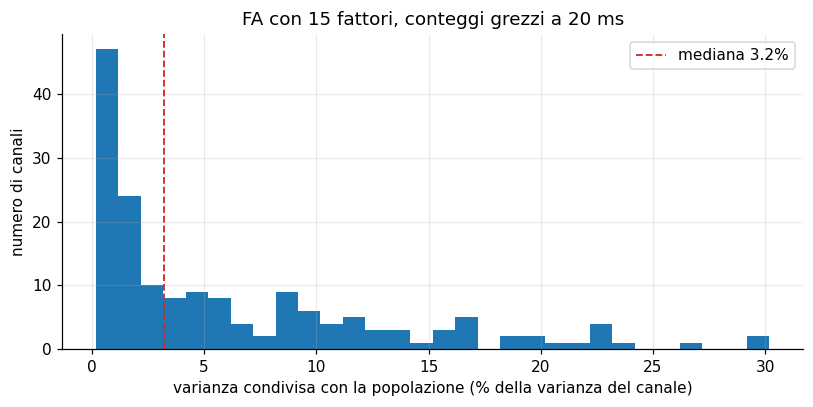

In [22]:
fa = FactorAnalysis(n_components=K_FA, svd_method="lapack", random_state=0).fit(X_fa)  # FA finale, su tutta la sessione
W_fa = fa.components_.T                                 # pesi: una riga per canale, una colonna per fattore (160 × K)
psi = fa.noise_variance_                                # varianza privata di ogni canale (la diagonale di Ψ)
shared = (W_fa ** 2).sum(axis=1)                        # varianza condivisa di ogni canale: somma dei suoi pesi al quadrato
frac_shared = shared / (shared + psi)                   # quota condivisa di ogni canale
print(f"Quota condivisa per canale: mediana {np.median(frac_shared):.3f}, "
      f"5°-95° percentile {np.percentile(frac_shared, 5):.3f}-{np.percentile(frac_shared, 95):.3f}, "
      f"massimo {frac_shared.max():.2f}")

fa_noz = FactorAnalysis(n_components=K_FA, svd_method="lapack", random_state=0).fit(X_counts.astype(float))  # stessa FA, senza z-score
sh_noz = (fa_noz.components_ ** 2).sum(axis=0)          # varianza condivisa senza z-score
frac_noz = sh_noz / (sh_noz + fa_noz.noise_variance_)   # quota condivisa senza z-score
print(f"Con e senza z-score, differenza massima nella quota condivisa: {np.abs(frac_noz - frac_shared).max():.4f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(frac_shared * 100, bins=30, color="C0")
ax.axvline(np.median(frac_shared) * 100, color="C3", ls="--", lw=1.2,
           label=f"mediana {np.median(frac_shared) * 100:.1f}%")
ax.set(xlabel="varianza condivisa con la popolazione (% della varianza del canale)", ylabel="numero di canali",
       title=f"FA con {K_FA} fattori, conteggi grezzi a 20 ms")
ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "02new_fa_shared.png", bbox_inches="tight"); plt.show()

**Lettura.** In un canale tipico solo una piccola parte della varianza, pochi punti percentuali,
è condivisa con il resto della popolazione: **il resto è rumore privato**. È la spiegazione del
participation ratio altissimo della PCA (§6): la PCA contava anche questo rumore, la FA lo mette
da parte. La quota condivisa varia molto da canale a canale: alcuni canali sono molto più legati
alla popolazione di altri.

Con e senza z-score la quota condivisa è la stessa: come previsto, la FA non dipende dalla scala
dei canali.

### 9.3 · Quante dimensioni ha la parte condivisa?

I K* fattori non pesano tutti uguale. Guardiamo la struttura condivisa $W W^\top$: i suoi
autovalori dicono quanta varianza condivisa sta lungo ciascuna direzione. Per confrontarla con la
PCA usiamo **le stesse due misure per tutti i metodi**:

- **participation ratio** (come al §6): il "numero efficace" di dimensioni. Guarda soprattutto le
  direzioni grandi;
- **dimensioni per il 95%**: quante direzioni servono per arrivare al 95% della varianza. Conta
  anche le direzioni piccole, quindi è più sensibile al rumore. Per la FA, applicata alla parte
  condivisa, è la *dimensionalità condivisa* di Williamson et al. (2016).

In [23]:
eig_sh = np.linalg.eigvalsh(W_fa @ W_fa.T)[::-1][:K_FA]  # varianze della parte condivisa, dalla più grande (le altre sono 0)
cum_sh = np.cumsum(eig_sh) / eig_sh.sum()               # varianza condivisa cumulativa

def n95(v):                                             # quante direzioni servono per il 95% di una varianza
    return int(np.searchsorted(np.cumsum(v) / v.sum(), 0.95) + 1)

d_shared = n95(eig_sh)                                  # dimensionalità condivisa: direzioni per il 95% della parte condivisa
pr_shared = pr(eig_sh)                                  # participation ratio della parte condivisa: la stessa misura della PCA
print(f"Parte condivisa: participation ratio {pr_shared:.1f}, dimensioni per il 95%: {d_shared}, "
      f"prime 3 direzioni: {cum_sh[2] * 100:.0f}% della varianza condivisa")

display(pd.DataFrame(
    [["PCA su tutti i bin (σ = 50 ms)", "segnale + tutto il rumore", PR, n95(lam)],
     ["PCA sulle medie per condizione", "segnale + rumore rimasto dopo la media", pr(lam_avg), n95(lam_avg)],
     [f"FA su tutti i bin, conteggi grezzi (K* = {K_FA})", "solo la parte condivisa tra canali", pr_shared, d_shared]],
    columns=["metodo", "che cosa conta", "participation ratio", "dimensioni per il 95%"]).set_index("metodo").round(1))

Parte condivisa: participation ratio 9.1, dimensioni per il 95%: 14, prime 3 direzioni: 48% della varianza condivisa


,che cosa conta,participation ratio,dimensioni per il 95%
metodo,,,
PCA su tutti i bin (σ = 50 ms),segnale + tutto il rumore,94.4,143
PCA sulle medie per condizione,segnale + rumore rimasto dopo la media,21.6,79
"FA su tutti i bin, conteggi grezzi (K* = 15)",solo la parte condivisa tra canali,9.1,14


**Lettura.**

- **Con la stessa misura (participation ratio)** la FA sui bin singoli trova circa 9.5 dimensioni
  efficaci, **senza fare nessuna media**: meno delle medie per condizione (~20) e lontanissimo
  dalle ~106 della PCA. Le medie di 7-8 ripetizioni contengono ancora molto rumore (§8), la FA
  lo mette da parte.
- **Con le dimensioni per il 95%** la differenza è ancora più netta: alla PCA sulle medie ne
  servono 78, alla FA 14. Il rumore rimasto dopo la media, anche se piccolo, è sparso su tante
  direzioni, e le ultime percentuali di varianza sono quasi tutte rumore.

Attenzione: qui la FA usa tutta la sessione (comprese le pause tra un movimento e l'altro), le
medie solo il primo secondo di ogni fase. Il confronto alla pari, sugli stessi istanti, è al §9.6.

### 9.4 · Le traiettorie single-trial sono più pulite?

La FA ci dice **quanto** segnale condiviso c'è. Ma le traiettorie di un singolo trial sono
migliori di quelle della PCA? Usiamo le finestre da 1 s del §8 e le prime 3 dimensioni latenti,
con due misure:

- **seghettatura** (*roughness*): quanto la traiettoria salta da un bin all'altro. Più bassa =
  più liscia;
- **consistenza**: quanto si somigliano le ripetizioni della stessa condizione, cioè stessa fase
  **e** stessa versione del task (§8): correlazione media tra le coppie di ripetizioni, calcolata
  in ognuna delle 16 condizioni e poi mediata. Più alta = meglio: ripetizioni dello stesso
  movimento dovrebbero somigliarsi. Ripetizioni di versioni diverse non si confrontano, perché il
  movimento è diverso.

Per un confronto equo, PCA e FA ricevono **gli stessi dati** (conteggi grezzi). Aggiungiamo PCA e
FA sui dati smussati (σ = 50 ms) come riferimento, per vedere quanto conta lo smoothing.

I fattori della FA non hanno un ordine naturale: si possono ruotare senza cambiare il modello. Li
ruotiamo in modo che siano **ordinati come le componenti della PCA**, dal più importante (con la
SVD di W, come farà GPFA).

In [24]:
def orth_latents(fa_, X):                               # fattori FA ruotati e ordinati dal più importante
    U_, S_, Vt_ = np.linalg.svd(fa_.components_.T, full_matrices=False)  # W = U · S · Vt
    return fa_.transform(X) @ Vt_.T * S_                # coordinate lungo le direzioni U, ordinate per importanza (S)

def roughness(trajs):                                   # seghettatura media di una lista di traiettorie (bin × dimensioni)
    return float(np.mean([(np.diff((T_ - T_.mean(0)) / (T_.std(0) + 1e-9), n=2, axis=0) ** 2).mean()
                          for T_ in trajs]))            # z-score di ogni dimensione, poi differenza seconda al quadrato

def consistency_w(trajs, win_list, per_phase=False):    # correlazione media tra ripetizioni della stessa condizione (fase, versione)
    conds_ = [cond_of(w) for w in win_list]
    out = {}
    for c in CONDS:
        R = np.stack([tr for tr, cw in zip(trajs, conds_) if cw == c])  # (ripetizioni, bin, 3 dimensioni)
        out[c] = np.mean([np.corrcoef(R[:, :, j])[np.triu_indices(len(R), 1)].mean()  # tutte le coppie di ripetizioni
                          for j in range(R.shape[2])])                              # per ogni dimensione, poi media
    if per_phase:                                       # per fase: media delle due versioni
        return {ph: (out[(ph, "dispari")] + out[(ph, "pari")]) / 2 for ph in io.MOVEMENT_PHASES}
    return float(np.mean(list(out.values())))           # media sulle 16 condizioni

def consistency(trajs):                                 # la consistenza sulle finestre da 1 s del §8
    return consistency_w(trajs, windows)

fa_sm = FactorAnalysis(n_components=K_FA, svd_method="lapack", random_state=0).fit(Z)  # stessa FA sui dati smussati del §5
latents = {
    "PCA, conteggi grezzi": PCA(3).fit_transform(X_fa),
    f"FA, conteggi grezzi (K = {K_FA})": orth_latents(fa, X_fa)[:, :3],
    "PCA, smussati σ = 50 ms": scores[:, :3],
    f"FA, smussati σ = 50 ms (K = {K_FA})": orth_latents(fa_sm, Z)[:, :3],
}
rows = []
for name, lat in latents.items():
    trajs = [lat[w["start"]:w["stop"]] for w in windows]  # le finestre da 1 s, per ogni metodo
    rows.append({"metodo": name, "seghettatura (più bassa = meglio)": roughness(trajs),
                 "consistenza (più alta = meglio)": consistency(trajs)})
tab_traj = pd.DataFrame(rows).set_index("metodo").round(3)
display(tab_traj)

,seghettatura (più bassa = meglio),consistenza (più alta = meglio)
metodo,,
"PCA, conteggi grezzi",5.721,0.055
"FA, conteggi grezzi (K = 15)",5.672,0.057
"PCA, smussati σ = 50 ms",0.010,0.165
"FA, smussati σ = 50 ms (K = 15)",0.010,0.166


In [25]:
# REPLICA: solo le definizioni della cella tolta 52
def fa_summary(X, K):                                   # quota condivisa mediana, PR e dimensioni per il 95% di una FA
    f_ = FactorAnalysis(n_components=K, svd_method="lapack", random_state=0).fit(X)
    W_ = f_.components_.T
    sh_ = (W_ ** 2).sum(axis=1)
    e_ = np.linalg.eigvalsh(W_ @ W_.T)[::-1][:K]
    return np.median(sh_ / (sh_ + f_.noise_variance_)), pr(e_), n95(e_)

**Lettura.**

- **La quota condivisa sale con σ.** Lo smoothing toglie soprattutto il rumore privato, che cambia
  da un bin all'altro, mentre il segnale condiviso, più lento, resta. La parte condivisa diventa
  quindi una fetta più grande del totale. Non è comparso segnale nuovo: stiamo guardando scale di
  tempo più lente. Per questo la quota condivisa va sempre riportata con il σ (o con "conteggi
  grezzi a 20 ms").
- **La dimensionalità della FA cambia poco**: con qualunque σ il PR condiviso resta tra circa
  9.5 e 13, e le dimensioni per il 95% tra 14 e 18. Il participation ratio della PCA, sugli stessi
  dati, passa invece da ~150 a ~85. La FA non conta il rumore privato come dimensioni, e per
  questo la sua stima dipende molto meno dal preprocessing. È un buon argomento per preferire la
  FA alla PCA quando si vuole dire "quante dimensioni".

### 9.6 · Confronto alla pari: la FA sugli stessi istanti delle medie

Al §9.3 la FA usava tutta la sessione, comprese le pause tra un movimento e l'altro, mentre la
PCA sulle medie usava solo il primo secondo di ogni fase. Qui rifacciamo la FA **solo sui bin che
cadono nelle finestre delle fasi**, cioè negli stessi istanti della PCA sulle medie, ma **senza
fare la media**: bin singoli, conteggi grezzi. Accanto mettiamo la PCA sugli stessi bin singoli.

Alcune finestre si sovrappongono: una fase breve, come `SnapTo`, dura meno di 1 s e la sua
finestra sconfina nella fase dopo. I bin in comune li contiamo una volta sola. Il numero di
fattori lo scegliamo di nuovo con la cross-validation, su questi bin (5 blocchi contigui, come
al §9.1).

In [26]:
K_GRID = [10]                                           # REPLICA: il K* del 02_new §9.6 (10), senza rifare la CV

In [27]:
in_win = np.zeros(n_bins, dtype=bool)                   # un vero/falso per ogni bin della sessione, tutti falsi all'inizio
for w in windows:                                       # segna come veri i bin di ogni finestra delle fasi
    in_win[w["start"]:w["stop"]] = True
X_win = X_fa[in_win]                                    # solo i bin nelle finestre, in ordine di tempo (conteggi grezzi z-scored)
print(f"{len(windows)} finestre × {L} bin = {len(windows) * L} bin, di cui {in_win.sum()} distinti")

folds_win = list(KFold(n_splits=5, shuffle=False).split(X_win))  # 5 blocchi contigui di questi bin
res_win = Parallel(n_jobs=-1)(delayed(cv_score)(X_win, K, tr, te)  # cross-validation, come al §9.1
                              for K in K_GRID for tr, te in folds_win)
cv_win = np.array(res_win).reshape(len(K_GRID), len(folds_win)).mean(axis=1)  # un voto per ogni K
K_WIN = K_GRID[int(np.argmax(cv_win))]                  # il K con il voto più alto
print("Log-likelihood sui dati mai visti:", dict(zip(K_GRID, cv_win.round(3))), f"-> K* = {K_WIN}")

fa_win = FactorAnalysis(n_components=K_WIN, svd_method="lapack", random_state=0).fit(X_win)  # FA finale su questi bin
W_win = fa_win.components_.T                            # pesi: 160 canali × K fattori
eig_win = np.linalg.eigvalsh(W_win @ W_win.T)[::-1][:K_WIN]  # varianze della parte condivisa, dalla più grande

lam_win_sm = PCA().fit(Z[in_win]).explained_variance_   # PCA sugli stessi bin singoli, smussati (come le medie)
lam_win_raw = PCA().fit(X_win).explained_variance_      # PCA sugli stessi bin singoli, grezzi (come la FA)
display(pd.DataFrame(
    [["PCA sulle medie per condizione", "media di 7-8 ripetizioni, smussati", pr(lam_avg), n95(lam_avg)],
     ["PCA sui bin singoli (smussati)", "nessuna media, smussati σ = 50 ms", pr(lam_win_sm), n95(lam_win_sm)],
     ["PCA sui bin singoli (grezzi)", "nessuna media, conteggi grezzi", pr(lam_win_raw), n95(lam_win_raw)],
     [f"FA sui bin singoli (K* = {K_WIN})", "nessuna media, conteggi grezzi", pr(eig_win), n95(eig_win)]],
    columns=["metodo", "dati (sempre gli stessi istanti)", "participation ratio", "dimensioni per il 95%"]
).set_index("metodo").round(1))

119 finestre × 50 bin = 5950 bin, di cui 5510 distinti


Log-likelihood sui dati mai visti: {10: np.float64(-233.91)} -> K* = 10


,dati (sempre gli stessi istanti),participation ratio,dimensioni per il 95%
metodo,,,
PCA sulle medie per condizione,"media di 7-8 ripetizioni, smussati",21.6,79
PCA sui bin singoli (smussati),"nessuna media, smussati σ = 50 ms",87.2,138
PCA sui bin singoli (grezzi),"nessuna media, conteggi grezzi",150.0,153
FA sui bin singoli (K* = 10),"nessuna media, conteggi grezzi",6.9,9


**Lettura.** È il confronto più pulito del notebook: stessi istanti, stesse misure.

- **Senza media, la PCA vede tantissime dimensioni** (~92 sui dati smussati, ~146 sui grezzi):
  il rumore.
- **Con la media per condizione, la PCA scende a ~20.**
- **La FA, senza nessuna media, scende molto più in basso: circa 7.** Ottiene dai bin singoli
  più di quello che la PCA ottiene mediando 7-8 ripetizioni.

Perché la FA scende sotto le medie? Nelle medie resta rumore: la media di 7-8 ripetizioni non lo
cancella del tutto (la curva del §8 non si era ancora fermata), e quel rumore aggiunge dimensioni.
La FA invece lo mette da parte. Si vede bene nella colonna del 95%: alle medie servono 78
direzioni, alla FA 9.

Qui la cross-validation sceglie meno fattori che su tutta la sessione (K* = 10 invece di 15). In
parte perché i dati sono circa la metà, in parte perché questi istanti sono meno vari: solo
l'inizio delle fasi di movimento, niente pause. Anche qui la curva è piatta intorno al massimo.

**Riassunto della FA.** La FA risolve il problema del *quanto*: separa il segnale condiviso dal
rumore privato e, **senza fare medie**, trova una struttura di circa 7-10 dimensioni efficaci,
più compatta di quella delle medie per condizione (che conservano un po' di rumore) e stabile
rispetto a σ. Non risolve il problema del *come
nel tempo*: le traiettorie single-trial restano rumorose quanto quelle della PCA (§9.4). Il passo
successivo, GPFA, aggiunge proprio il modello del tempo.

## 10 · GPFA: aggiungere il modello del tempo

### L'idea

La FA (§9) separa il segnale condiviso dal rumore di ogni canale, ma guarda **ogni bin da solo**:
non sa che il bin di adesso e quello di 20 ms fa sono vicini nel tempo. Per questo le sue
traiettorie restano seghettate (§9.4).

La **GPFA** (*Gaussian Process Factor Analysis*, Yu et al. 2009) è una FA con un'idea in più:
**ogni fattore cambia in modo graduale nel tempo**. Per ogni bin il modello è lo stesso della FA,

$$y(t) = C\,x(t) + d + \varepsilon(t), \qquad \varepsilon(t) \sim \mathcal{N}(0, R), \ R \text{ diagonale}$$

ma in più ogni fattore $x_i(t)$ segue un *processo gaussiano*: due istanti vicini hanno valori
simili, e quanto devono essere vicini lo dice una **scala di tempo** $\tau_i$, diversa per ogni
fattore e **imparata dai dati**:

$$\text{somiglianza tra } x_i(t_1) \text{ e } x_i(t_2) = \exp\!\left(-\frac{(t_1 - t_2)^2}{2\tau_i^2}\right)$$

Per esempio, con τ = 200 ms due istanti a 200 ms di distanza si somigliano ancora al 60%, a
600 ms quasi per niente.

**Cosa cambia in pratica.** Per stimare i fattori in un istante, la GPFA usa i 160 conteggi di
quell'istante **e anche quelli degli istanti vicini**, pesati secondo τ e secondo il rumore di
ciascun canale. È come fare FA e smoothing insieme, con una differenza importante: **quanto
smussare lo impara la GPFA**, per ogni fattore, invece di sceglierlo noi come il σ del §4.

### Le scelte, e perché

1. **Le "prove" sono le 119 finestre da 1 s** dall'inizio di ogni fase (§8). La GPFA ha bisogno di
   sequenze che si ripetono; usiamo le stesse finestre della PCA sulle medie e della FA del §9.6,
   così i confronti sono alla pari.
2. **Gli stessi bin di tutto il notebook.** `elephant` ha un suo modo di raggruppare gli spike in
   bin che, per arrotondamenti nei tempi, non coincide con il nostro (lo verifichiamo qui sotto).
   Diamo quindi alla GPFA direttamente i nostri conteggi, finestra per finestra, usando le
   funzioni di calcolo di `elephant` (`gpfa_core`).
3. **La radice quadrata dei conteggi**, come nell'articolo originale e come fa `elephant` di
   default. Nei conteggi il rumore cresce con il firing rate (§5); con la radice diventa simile
   per canali lenti e veloci. Per un confronto alla pari, al §10.4 diamo la radice dei conteggi
   anche alla FA.
4. **Un punto di partenza fisso.** La GPFA parte da una FA che ha un elemento casuale: fissiamo il
   seme, così ogni esecuzione dà lo stesso risultato.

In [28]:
import contextlib, logging, os, warnings                # strumenti per silenziare i messaggi di elephant
import quantities as pq                                 # unità di misura (ms), richieste da elephant
from elephant.gpfa import gpfa_core                     # le funzioni di calcolo della GPFA di elephant
from elephant.conversion import BinnedSpikeTrain        # il binning di elephant, solo per il confronto qui sotto
import elephant.utils

elephant.utils.logger.setLevel(logging.ERROR)           # elephant stampa molti avvisi innocui: li nascondiamo
warnings.filterwarnings("ignore")
BIN_MS = BIN_S * 1000                                   # larghezza del bin in ms (20), come la vuole elephant

sts = io.windows_spiketrains(s, windows, units=ACTIVE)  # per ogni finestra, i 160 spike train (tempi dall'inizio della finestra)
diff_bins = sum(int((BinnedSpikeTrain(st, bin_size=BIN_MS * pq.ms).to_array().T  # conteggi secondo elephant...
                     != X_counts[w["start"]:w["stop"]]).sum())                      # ...confrontati con i nostri
                for st, w in zip(sts, windows))
print(f"Bin con conteggi diversi tra il binning di elephant e il nostro: {diff_bins} "
      f"su {len(windows) * L * len(ACTIVE):,}")

def make_seqs(win_list):                                # i dati nel formato che vuole elephant: una riga per finestra
    return np.array([(w["stop"] - w["start"],                     # T: numero di bin della finestra (50)
                      np.sqrt(X_counts[w["start"]:w["stop"]].T))  # y: radice dei conteggi, canali × bin
                     for w in win_list], dtype=[("T", int), ("y", "O")])

def fit_gpfa(win_list, d, iters=500, tau_init=100.0, whole=False):  # stima una GPFA con d fattori sulle finestre indicate
    np.random.seed(0)                                   # punto di partenza fisso (la FA iniziale ha una parte casuale)
    cut_orig = gpfa_core.gpfa_util.cut_trials           # la funzione di elephant che spezza le finestre in pezzi da 20 bin
    if whole:                                           # whole=True: niente pezzi, la stima usa le finestre intere (§10.6)
        gpfa_core.gpfa_util.cut_trials = lambda seqs, seg_length=np.inf: cut_orig(seqs, seg_length=np.inf)
    try:
        with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):  # nasconde i messaggi di avanzamento
            params, info = gpfa_core.fit(make_seqs(win_list), x_dim=d, bin_width=BIN_MS,
                                         em_max_iters=iters, tau_init=tau_init)
    finally:
        gpfa_core.gpfa_util.cut_trials = cut_orig       # in ogni caso rimettiamo a posto la funzione originale
    return params, info

def gpfa_ll_per_bin(params, win_list):                  # log-likelihood media per bin su finestre mai viste
    _, ll = gpfa_core.exact_inference_with_ll(make_seqs(win_list), params, get_ll=True)
    return ll / sum(w["stop"] - w["start"] for w in win_list)

Bin con conteggi diversi tra il binning di elephant e il nostro: 586 su 981,750


In [29]:
# REPLICA: solo le definizioni della cella tolta 62
def cv_gpfa(d, train, test):                            # una stima: GPFA sulle finestre "train", due voti
    params, _ = fit_gpfa([windows[i] for i in train], d)
    return (gpfa_ll_per_bin(params, [windows[i] for i in train]),   # voto sui dati di studio
            gpfa_ll_per_bin(params, [windows[i] for i in test]))

In [30]:
D_GP = 25                                               # REPLICA: i fattori scelti nel 02_new (§10.2), senza rifare la CV

fattore (dal più veloce),1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
partenza 50 ms,44.0,52.0,53.0,59.0,63.0,65.0,67.0,69.0,92.0,100.0,...,140.0,206.0,216.0,223.0,307.0,329.0,552.0,626.0,627.0,857.0
partenza 100 ms (scelta),51.0,62.0,72.0,86.0,88.0,102.0,105.0,110.0,111.0,117.0,...,192.0,229.0,292.0,317.0,346.0,492.0,607.0,777.0,895.0,1268.0
partenza 200 ms,57.0,75.0,80.0,85.0,96.0,104.0,116.0,124.0,145.0,145.0,...,250.0,328.0,330.0,537.0,546.0,564.0,595.0,908.0,1210.0,1228.0


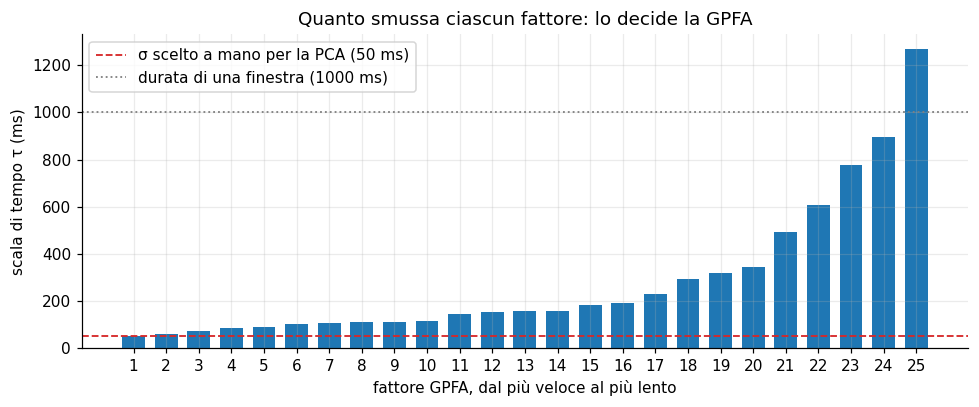

In [31]:
params_gp, _ = fit_gpfa(windows, D_GP)                  # GPFA finale, su tutte le finestre
tau_gp = np.sort(BIN_MS / np.sqrt(params_gp["gamma"]))  # scala di tempo di ogni fattore, in ms (da gamma, come in elephant)

alt = Parallel(n_jobs=-1)(delayed(fit_gpfa)(windows, D_GP, tau_init=t0)  # stesse stime con partenze diverse
                          for t0 in (50.0, 200.0))
tau_alt = {t0: np.sort(BIN_MS / np.sqrt(p["gamma"])) for t0, (p, _) in zip((50.0, 200.0), alt)}
display(pd.DataFrame({"partenza 50 ms": tau_alt[50.0], "partenza 100 ms (scelta)": tau_gp,
                      "partenza 200 ms": tau_alt[200.0]},
                     index=pd.Index(np.arange(1, D_GP + 1), name="fattore (dal più veloce)")).round(0).T)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(np.arange(1, D_GP + 1), tau_gp, color="C0", width=0.7)
ax.axhline(SIGMA_MS, color="C3", ls="--", lw=1.2, label=f"σ scelto a mano per la PCA ({SIGMA_MS} ms)")
ax.axhline(WIN_S * 1000, color="0.5", ls=":", lw=1.2, label="durata di una finestra (1000 ms)")
ax.set(xlabel="fattore GPFA, dal più veloce al più lento", ylabel="scala di tempo τ (ms)",
       title="Quanto smussa ciascun fattore: lo decide la GPFA", xticks=np.arange(1, D_GP + 1))
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIGS / "02new_gpfa_timescales.png", bbox_inches="tight"); plt.show()

**Lettura.**

- La GPFA ha imparato scale di tempo che vanno da **circa 50 ms** (il fattore più veloce, simile
  al nostro σ) a **diverse centinaia di ms**. Non c'è un σ unico giusto per tutti: alcuni fattori
  cambiano in fretta, altri lentamente. È quello che uno smoothing scelto a mano non può fare.
- **Il fattore più veloce è stabile**: τ ≈ 45-50 ms comunque si parta.
- **Gli altri si spostano con il punto di partenza**: partendo da 50 ms escono più brevi, partendo
  da 200 ms più lunghi, e i più lenti cambiano di più (fino a ~900 ms). Un motivo possibile è che
  durante la stima `elephant` guarda pezzi da 400 ms (§10.1), dentro i quali un fattore lento è
  quasi costante. Al §10.6 proviamo a stimare sulle finestre intere, e vediamo che non basta: le
  scale lente restano indeterminate. I dati dicono chiaramente che accanto a
  un fattore veloce ci sono fattori lenti, da ~100 ms a molte centinaia di ms, ma non fissano con
  precisione il valore di ciascuno. Il messaggio affidabile è l'intervallo, non il singolo numero.

### 10.4 · Quante dimensioni vede la GPFA?

La parte condivisa della GPFA è $C C^\top$, esattamente come $W W^\top$ nella FA: possiamo
calcolare le stesse misure. Per isolare l'effetto del tempo, la confrontiamo con una **FA sugli
stessi dati** (radice dei conteggi, stessi bin delle finestre) **e con lo stesso numero di
fattori**: l'unica differenza tra le due è il modello del tempo. Per vedere quanto il risultato
dipende dal numero di fattori, rifacciamo sia la FA sia la GPFA con 10, 15, 20, 25 e 30 fattori.

In [32]:
def shared_stats(C_, psi_):                             # PR, dimensioni per il 95% e quota condivisa mediana
    e_ = np.linalg.eigvalsh(C_ @ C_.T)[::-1][:C_.shape[1]]  # varianze della parte condivisa, dalla più grande
    sh_ = (C_ ** 2).sum(axis=1)                         # varianza condivisa di ogni canale
    return pr(e_), n95(e_), np.median(sh_ / (sh_ + psi_)) * 100

X_sqrt = np.sqrt(X_counts)                              # radice dei conteggi, tutti i bin
D_TAB = [D_GP]                                          # REPLICA: solo il valore scelto                            # numeri di fattori per la tabella

other_d = [d for d in D_TAB if d != D_GP]               # la GPFA con D_GP ce l'abbiamo già (§10.3)
gp_fits = dict(zip(other_d, Parallel(n_jobs=-1)(delayed(fit_gpfa)(windows, d) for d in other_d)))
gp_fits[D_GP] = (params_gp, None)
fa_fits = {d: FactorAnalysis(n_components=d, svd_method="lapack", random_state=0).fit(X_sqrt[in_win])
           for d in D_TAB}                              # FA sugli stessi bin, con lo stesso numero di fattori
fa_sq = fa_fits[D_GP]                                   # la FA con D_GP fattori, usata anche al §10.5

rows = []
for d in D_TAB:
    g_pr, g_95, g_sh = shared_stats(gp_fits[d][0]["C"], np.diag(gp_fits[d][0]["R"]))  # misure della GPFA
    f_pr, f_95, f_sh = shared_stats(fa_fits[d].components_.T, fa_fits[d].noise_variance_)  # misure della FA
    rows.append({"fattori": d, "GPFA: participation ratio": g_pr, "FA: participation ratio": f_pr,
                 "GPFA: dimensioni per il 95%": g_95, "FA: dimensioni per il 95%": f_95,
                 "GPFA: quota condivisa mediana (%)": g_sh, "FA: quota condivisa mediana (%)": f_sh})
display(pd.DataFrame(rows).set_index("fattori").round(1))

,GPFA: participation ratio,FA: participation ratio,GPFA: dimensioni per il 95%,FA: dimensioni per il 95%,GPFA: quota condivisa mediana (%),FA: quota condivisa mediana (%)
fattori,,,,,,
25,11.6,12.9,21,21,3.9,6.5


**Lettura.**

- **Sul "quante dimensioni" GPFA e FA sono d'accordo**: a ogni numero di fattori il
  participation ratio della parte condivisa è quasi lo stesso (la GPFA è sempre un po' più bassa).
  Aggiungere il tempo non cambia *quanta* struttura condivisa c'è.
- **Il numero cresce con i fattori, senza fermarsi**: da circa 6.5 con 10 fattori a circa 13.4
  con 30. I fattori in più non sono vuoti: portano una parte della varianza condivisa. Per questo
  il numero di dimensioni va sempre dichiarato insieme al numero di fattori, come il σ per la PCA.
- **Con i 25 fattori scelti al §10.2 il participation ratio è circa 12** (e servono circa 21
  direzioni per il 95% della parte condivisa). Con 20 fattori sarebbe stato circa 10.5: la scelta
  del numero di fattori sposta il risultato di circa il 16%, ed è il motivo per cui la scelta va
  fatta con la cross-validation e non a occhio. In ogni caso sono poche dimensioni rispetto alle
  ~100 della PCA.
- La quota condivisa della GPFA è un po' più bassa di quella della FA: la GPFA considera
  "condiviso" solo ciò che è condiviso **e** cambia gradualmente. Le fluttuazioni comuni ma
  rapidissime finiscono nel rumore privato.

### 10.5 · Le traiettorie single-trial: finalmente pulite?

Il confronto decisivo, sulle stesse finestre e con le stesse due misure del §9.4 (seghettatura e
consistenza tra ripetizioni, prime 3 dimensioni). Tutti i metodi sono stimati **sugli stessi bin
delle finestre**:

- PCA sui conteggi grezzi e PCA sui dati smussati a σ = 50 ms;
- FA sulla radice dei conteggi, con lo stesso numero di fattori della GPFA: è "la GPFA senza il
  tempo";
- GPFA.

Le traiettorie della GPFA si ottengono stimando i fattori in ogni finestra e ruotandoli in modo
che siano ordinati per importanza, come le componenti della PCA (`orthonormalize` di `elephant`).

In [33]:
seq_lat, _ = gpfa_core.exact_inference_with_ll(make_seqs(windows), params_gp, get_ll=False)  # fattori in ogni finestra
_, seq_orth = gpfa_core.orthonormalize(params_gp, seq_lat)  # fattori ruotati e ordinati per importanza
G = [x.T for x in seq_orth["latent_variable_orth"]]     # per ogni finestra: (50 bin, d fattori)

pca_raw_w = PCA(3).fit(X_fa[in_win])                    # PCA sui conteggi grezzi, stimata sui bin delle finestre
pca_sm_w = PCA(3).fit(Z[in_win])                        # PCA sui dati smussati, stimata sui bin delle finestre
z_fa_sq = orth_latents(fa_sq, X_sqrt)                   # FA sulla radice dei conteggi, fattori ordinati (§9.4)

traj = {
    "PCA, conteggi grezzi": [pca_raw_w.transform(X_fa[w["start"]:w["stop"]]) for w in windows],
    "PCA, smussati σ = 50 ms": [pca_sm_w.transform(Z[w["start"]:w["stop"]]) for w in windows],
    f"FA, radice dei conteggi (K = {D_GP})": [z_fa_sq[w["start"]:w["stop"], :3] for w in windows],
    f"GPFA, radice dei conteggi (d = {D_GP})": [g[:, :3] for g in G],
}
rows = []
for name, tr in traj.items():
    rows.append({"metodo": name, "seghettatura (più bassa = meglio)": roughness(tr),
                 "consistenza (più alta = meglio)": consistency(tr)})
tab_final = pd.DataFrame(rows).set_index("metodo")
display(tab_final.round(4))

display(pd.DataFrame({name: consistency_w(tr, windows, per_phase=True)  # la consistenza fase per fase
                     for name, tr in traj.items()}).T.round(2)              # (media delle due versioni)
        .rename_axis(columns="consistenza per fase (media delle due versioni)"))

,seghettatura (più bassa = meglio),consistenza (più alta = meglio)
metodo,,
"PCA, conteggi grezzi",5.7806,0.0564
"PCA, smussati σ = 50 ms",0.0100,0.1533
"FA, radice dei conteggi (K = 25)",5.7409,0.0577
"GPFA, radice dei conteggi (d = 25)",0.0049,0.1549


consistenza per fase (media delle due versioni),Reach,Orient,SnapTo,Shape,Grasp,Carry,Orient2,Release
"PCA, conteggi grezzi",-0.01,0.01,0.01,0.09,0.13,0.02,0.01,0.19
"PCA, smussati σ = 50 ms",-0.01,0.03,0.03,0.24,0.38,0.12,0.05,0.39
"FA, radice dei conteggi (K = 25)",-0.01,0.01,0.01,0.09,0.11,0.02,0.02,0.20
"GPFA, radice dei conteggi (d = 25)",-0.04,0.07,0.05,0.28,0.30,0.13,0.05,0.40


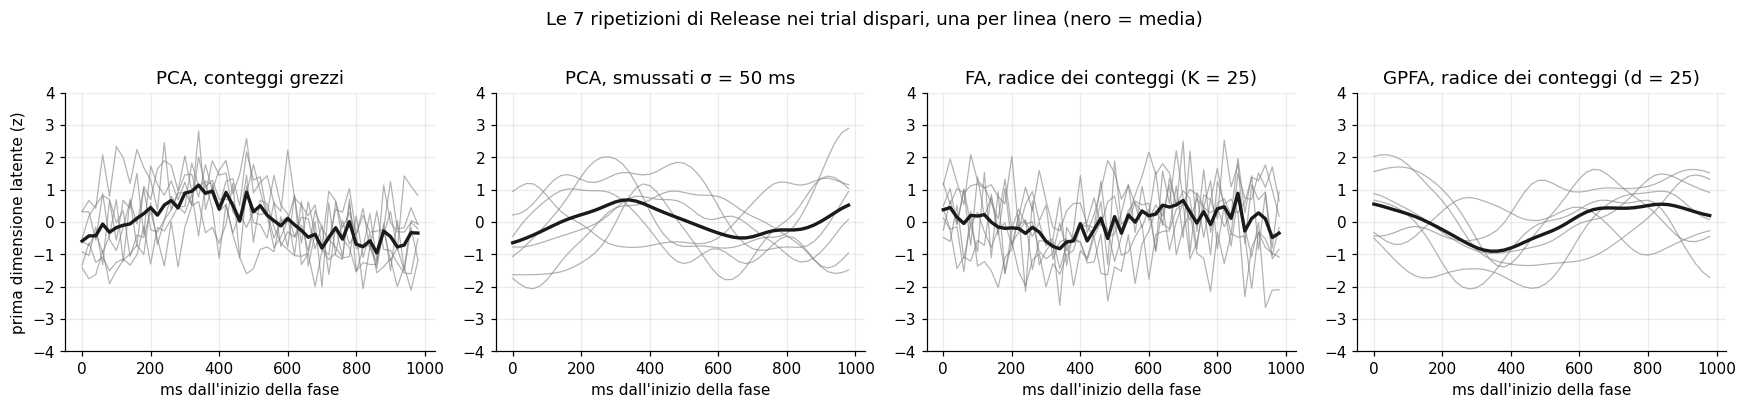

In [34]:
PH_SHOW = ("Release", "dispari")                        # una condizione ben modulata, per la figura
idx_ph = [i for i, w in enumerate(windows) if cond_of(w) == PH_SHOW]  # le sue ripetizioni
t_win = np.arange(L) * BIN_S * 1000                     # tempo dall'inizio della fase, in ms

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for k, (name, tr) in enumerate(traj.items()):
    R = np.stack([tr[i][:, 0] for i in idx_ph])         # prima dimensione di ogni ripetizione: (ripetizioni, 50)
    R = (R - R.mean()) / R.std()                        # stessa scala per tutti i metodi
    for r in R:
        ax[k].plot(t_win, r, color=io.PHASE_COLORS[PH_SHOW[0]], lw=0.8, alpha=0.6)  # ogni ripetizione, sottile
    ax[k].plot(t_win, R.mean(axis=0), color="0.1", lw=2.2)                        # la loro media, spessa
    ax[k].set(title=name, xlabel="ms dall'inizio della fase", ylim=(-4, 4))
ax[0].set_ylabel("prima dimensione latente (z)")
fig.suptitle(f"Le {len(idx_ph)} ripetizioni di {PH_SHOW[0]} nei trial {PH_SHOW[1]}, una per linea (nero = media)", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "02new_gpfa_repetitions.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **La GPFA vince su entrambe le misure**: è la più liscia e quella in cui le ripetizioni della
  stessa condizione si somigliano di più (0.137 contro 0.117 della PCA smussata).
  Nella figura le ripetizioni di `Release` nei trial dispari sono lisce e seguono in gran parte lo
  stesso andamento (salgono nei primi ~200 ms e poi scendono), lo stesso che trova la PCA
  smussata, anche se con una certa dispersione; con PCA e FA sui conteggi grezzi sono una nuvola
  seghettata.
- Fase per fase, la GPFA è migliore su `Grasp` e `Release`, pari alla PCA smussata su `Shape`, un
  po' peggiore su `Reach`.
- **La FA con la radice dei conteggi si comporta come la PCA grezza**, anche se ha gli stessi dati
  e lo stesso numero di fattori della GPFA. L'unica differenza tra FA e GPFA è il modello del
  tempo: **è il tempo che pulisce le traiettorie**.
- Il salto più grande è da "nessun modello del tempo" a "un modello del tempo". Tra la PCA smussata
  a mano e la GPFA la differenza è più piccola; il vantaggio della GPFA è che non abbiamo dovuto
  scegliere σ, e che ogni fattore ha la sua scala di tempo.
- **Onestamente**, la consistenza resta bassa in assoluto per molte fasi (`Reach`, `Orient`,
  `SnapTo`, `Carry`, `Orient2` restano sotto 0.1 con tutti i metodi). Le fasi più riproducibili sono quelle della
  mano (`Shape`, `Grasp`, `Release`), coerentemente con la posizione degli array nell'area della
  mano della corteccia motoria.

### Le traiettorie GPFA nel piano, come al §8

Al §8 le traiettorie pulite si vedevano solo facendo la media delle ripetizioni. Con la GPFA
guardiamo **una sola ripetizione per condizione**. Gli assi sono le prime due dimensioni della
GPFA, stimate **senza sapere a quale condizione appartiene ogni finestra**.

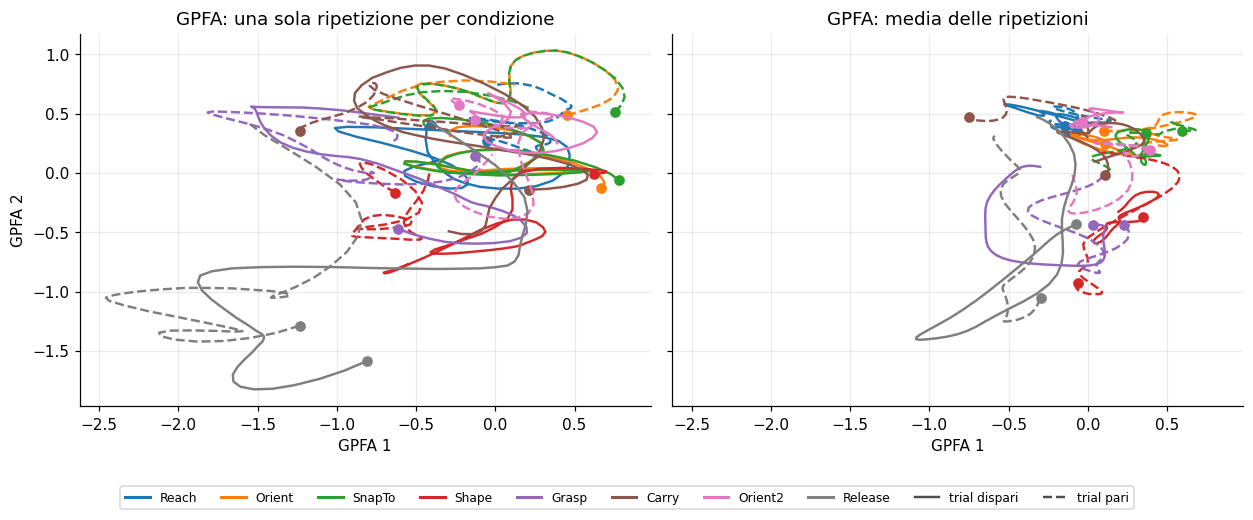

In [35]:
first = {c: next(i for i, w in enumerate(windows) if cond_of(w) == c) for c in CONDS}  # prima ripetizione di ogni condizione
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)
for (ph, v) in CONDS:
    one_gp = G[first[(ph, v)]][:, :2]                   # una ripetizione
    avg_gp = np.mean([G[i][:, :2] for i, w in enumerate(windows) if cond_of(w) == (ph, v)], axis=0)  # media delle ripetizioni
    for k, D_ in enumerate((one_gp, avg_gp)):
        ax[k].plot(D_[:, 0], D_[:, 1], color=io.PHASE_COLORS[ph], ls=VER_LS[v], lw=1.6)
        ax[k].plot(D_[0, 0], D_[0, 1], "o", color=io.PHASE_COLORS[ph], ms=6)  # pallino = inizio della fase
ax[0].set(xlabel="GPFA 1", ylabel="GPFA 2", title="GPFA: una sola ripetizione per condizione")
ax[1].set(xlabel="GPFA 1", title="GPFA: media delle ripetizioni")
handles = ([plt.Line2D([], [], color=io.PHASE_COLORS[ph], lw=2, label=ph) for ph in io.MOVEMENT_PHASES]
           + [plt.Line2D([], [], color="0.3", ls=VER_LS[v], lw=1.6, label=f"trial {v}") for v in VERSIONS])
fig.legend(handles=handles, ncol=10, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIGS / "02new_gpfa_plane.png", bbox_inches="tight"); plt.show()

**Lettura.** Rispetto al pannello centrale della figura del §8 (una ripetizione, PCA), le
traiettorie di una singola ripetizione sono **lisce**, non seghettate. Restano più disordinate
della media: la GPFA toglie il rumore rapido, ma una singola ripetizione non è mai identica alla
media, anche perché il movimento tentato cambia un po' ogni volta.

**Riassunto della GPFA.** La GPFA mette insieme i due ingredienti che servivano: il modello del
rumore della FA (quali canali sono affidabili) e un modello del tempo (gli istanti vicini si
somigliano), con scale di tempo imparate dai dati. Grazie al modello del tempo regge più fattori
della FA senza overfitting (25 contro 10). Sul *quante dimensioni*, a parità di fattori, è
d'accordo con la FA (circa 12 dimensioni efficaci con i 25 fattori scelti; il numero cresce con i
fattori);
sulle *traiettorie single-trial* è il metodo migliore tra quelli lineari, senza bisogno di fare
medie e senza scegliere σ a mano.

In [36]:
# REPLICA: solo le definizioni della cella tolta 74
def seg_job(kind, arg):                                 # una stima sulle finestre intere
    if kind == "tau":                                   # per le scale di tempo: tutte le finestre, partenza arg (ms)
        return fit_gpfa(windows, D_GP, tau_init=arg, whole=True)
    train, test = folds_gp[arg]                         # per il voto: il blocco numero arg fa da esame
    params, _ = fit_gpfa([windows[i] for i in train], D_GP, whole=True)
    return gpfa_ll_per_bin(params, [windows[i] for i in test])

def tau_table(tau_by_start, label):                     # riassunto delle scale di tempo per un modo di stimare
    A = np.stack([tau_by_start[t0] for t0 in TAU_STARTS])  # (3 partenze, 25 fattori), dal più veloce al più lento
    ratio = A.max(axis=0) / A.min(axis=0)               # per ogni fattore: quanto cambia tra le tre partenze
    rng_ = lambda v: f"{v.min():.0f}-{v.max():.0f}"     # intervallo tra le tre partenze
    return {"stima su": label, "fattore più veloce (ms)": rng_(A[:, 0]), "fattore di mezzo (ms)": rng_(A[:, D_GP // 2]),
            "fattore più lento (ms)": rng_(A[:, -1]),
            "fattori stabili (cambiano meno del 30%)": f"{int((ratio < 1.3).sum())} su {D_GP}"}

In [37]:
# REPLICA: solo le definizioni della cella tolta 79
def pr_avg(win_list, n, aligned=True, n_draws=20, seed=0):  # PR medio quando mediamo n ripetizioni (o n finestre casuali)
    rng_ = np.random.default_rng(seed)                  # seme fisso: estrazioni riproducibili
    L_ = win_list[0]["stop"] - win_list[0]["start"]     # bin per finestra
    reps_ = {c: np.stack([Z[w["start"]:w["stop"]] for w in win_list if cond_of(w) == c])  # (ripetizioni, bin, canali)
             for c in CONDS}
    out = []
    for _ in range(n_draws):
        if aligned:                                     # n ripetizioni vere di ogni condizione, mediate
            M = np.concatenate([reps_[c][rng_.choice(len(reps_[c]), n, replace=False)].mean(axis=0)
                                for c in CONDS])
        else:                                           # controllo: n finestre in punti a caso, mediate
            M = np.concatenate([np.mean([Z[a:a + L_] for a in rng_.integers(0, n_bins - L_, n)], axis=0)
                                for _ in CONDS])
        out.append(pr(PCA().fit(M).explained_variance_))
    return np.mean(out)

def window_trajs(win_list, gp_params):                  # le prime 3 dimensioni di PCA, FA e GPFA in ogni finestra
    mask = np.zeros(n_bins, dtype=bool)                 # i bin delle finestre, contati una volta sola
    for w in win_list:
        mask[w["start"]:w["stop"]] = True
    pca_r = PCA(3).fit(X_fa[mask])                      # PCA sui conteggi grezzi, stimata su questi bin
    pca_s = PCA(3).fit(Z[mask])                         # PCA sui dati smussati, stimata su questi bin
    fa_ = FactorAnalysis(n_components=D_GP, svd_method="lapack", random_state=0).fit(X_sqrt[mask])  # FA, stessi fattori della GPFA
    z_fa_ = orth_latents(fa_, X_sqrt)
    lat_, _ = gpfa_core.exact_inference_with_ll(make_seqs(win_list), gp_params, get_ll=False)  # fattori GPFA in ogni finestra
    _, orth_ = gpfa_core.orthonormalize(gp_params, lat_)
    return {"PCA, conteggi grezzi": [pca_r.transform(X_fa[w["start"]:w["stop"]]) for w in win_list],
            "PCA, smussati σ = 50 ms": [pca_s.transform(Z[w["start"]:w["stop"]]) for w in win_list],
            f"FA, radice dei conteggi (K = {D_GP})": [z_fa_[w["start"]:w["stop"], :3] for w in win_list],
            f"GPFA, radice dei conteggi (d = {D_GP})": [x.T[:, :3] for x in orth_["latent_variable_orth"]]}

## 11 · Riepilogo

| passo | parametro | perché | se lo cambiassimo |
|---|---|---|---|
| soglia (a monte, non nostra) | −4.5 × RMS, ricalcolata a ogni sessione | separa gli spike dal rumore di fondo; valore del laboratorio (Downey 2017, Quick 2020), non riportato da FALCON | non modificabile: non abbiamo la tensione grezza |
| 1 · binning | 20 ms | passo nativo del benchmark, allineato 1:1 alla cinematica | bisognerebbe ricampionare la cinematica |
| 2 · canali attivi | ≥ 0.5 Hz → 160 su 176 | i canali quasi silenti non portano informazione, hanno varianza ~0 e dopo lo z-score diventano outlier | 0.1 Hz ne esclude 1, 2 Hz ne esclude 46 |
| 3 · smoothing | gaussiano, σ = 50 ms | un bin da 20 ms contiene 0 o 1 eventi: serve una media pesata dei bin vicini per stimare il firing rate | il participation ratio va da ~150 (nessuno smoothing) a ~65 (σ = 200 ms), senza plateau (§6.1) |
| 4 · z-score | media 0, varianza 1 per canale | la varianza cresce con il firing rate: senza z-score la PC1 descrive i canali più attivi | alternativa: *soft normalization* (Churchland 2012) |
| 5 · PCA | tutte le componenti | direzioni di massima varianza della popolazione | — |
| PCA sulle medie | finestre da 1 s dall'inizio di ogni fase; 16 condizioni fase × versione del task, 7-8 ripetizioni | la media cancella il rumore e lascia il segnale del task; le due versioni (trial dispari e pari) sono movimenti diversi e non si mescolano | il confronto va fatto a parità di punti (§8) |
| FA | conteggi grezzi 20 ms, K scelto per cross-validation, SVD esatta | separa il segnale condiviso dal rumore privato di ogni canale | con lo smoothing la quota condivisa sale, la dimensionalità cambia poco (§9.5) |
| GPFA | radice dei conteggi, finestre da 1 s, 500 iterazioni, d per cross-validation | FA + scala di tempo imparata per ogni fattore: traiettorie single-trial lisce | a parità di fattori stesse dimensioni della FA; traiettorie migliori (§10.5) |

### Alternative provate in questo notebook

Ogni scelta è stata confrontata con delle alternative, cambiando un solo parametro alla volta.

| che cosa | valori provati | effetto | dove |
|---|---|---|---|
| soglia di rilevazione (segnale sintetico) | −3, −4.5, −6 × RMS | −3: eventi falsi dal rumore; −4.5: entrambi i neuroni; −6: perde spike del neurone lontano | §1 |
| soglia di attività dei canali | 0.1, 0.5, 1, 2, 5 Hz | esclude 1, 16, 28, 46, 72 canali su 176 | §3 |
| larghezza dello smoothing σ | 20, 50, 100 ms (figura); 0, 10, 20, 50, 100, 200 ms (PCA) | PR da ~150 a ~65, senza plateau: il numero dipende da σ, la conclusione qualitativa no | §4, §6.1 |
| normalizzazione | nessuna vs z-score | peso dei 10 canali più attivi nella PC1: 64% vs 21% | §5 |
| ripetizioni mediate | 1, 2, 4, 7; finestre allineate vs casuali | il PR (800 punti) scende da ~50 a ~21 solo con finestre allineate alle fasi | §8 |
| algoritmo della FA | SVD approssimata (default) vs esatta | la versione di default si ferma prima della soluzione | §9 |
| numero di fattori K | 2, 5, 10, 15, 20, 30 (cross-validation) | K* = 15, curva piatta tra 10 e 20 | §9.1 |
| z-score prima della FA | con / senza | quota condivisa identica: la FA non dipende dalla scala | §9.2 |
| metodo per le traiettorie | PCA vs FA, conteggi grezzi vs smussati | la FA non migliora le traiettorie single-trial; lo smoothing sì | §9.4 |
| smoothing prima della FA | σ = 0, 20, 50, 100 ms | quota condivisa ~4% → ~19%; dimensionalità della FA stabile (PR 9.5-13) | §9.5 |
| istanti usati dalla FA | tutta la sessione vs solo le finestre delle fasi | PR condiviso 9.5 → 7; K* 15 → 10 | §9.6 |
| durata della finestra | 0.5, 0.75, 1 s | calo del PR con la media simile (59-63%); stessa classifica dei metodi; consistenza più alta con 1 s | §10.7 |
| ripetizioni troppo corte | tutte vs senza le fasi < 100 ms (12 su 119) | stesso calo del PR; consistenza media ±0.01 (cambia solo `Orient`, rimasta con 4 ripetizioni) | §10.7 |
| binning per la GPFA | quello di elephant vs il nostro | pochi bin diversi (eventi sul bordo): usiamo il nostro | §10 |
| iterazioni della GPFA | 100 (notebook 02), 500, 1000 | a 100 non ha finito; 500 ≈ 1000 | §10.1 |
| numero di fattori d | 2, 5, 10, 15, 20, 25, 30, 40, 50 (cross-validation) | voto massimo a 25-30, poi scende (overfitting); scelto 25: batte 20 in 5 blocchi su 5, pari con 30 | §10.2 |
| scala di tempo iniziale | 50, 100, 200 ms | il τ più veloce (~45-50 ms) è stabile, gli altri si spostano: affidabile l'intervallo, non il singolo valore | §10.3 |
| pezzi usati per stimare la GPFA | 20 bin (default di elephant) vs finestre intere (50 bin) | le scale lente non si stabilizzano; voto sui dati mai visti +0.09 (5 blocchi su 5); stesse dimensioni; 7 volte più lento | §10.6 |
| fattori per FA e GPFA | 10, 15, 20, 25, 30 | PR condiviso da ~6.5 a ~13.4: cresce con i fattori; FA e GPFA d'accordo a ogni valore | §10.4 |
| FA vs GPFA a parità di dati e fattori | con / senza modello del tempo | stesse dimensioni; solo la GPFA pulisce le traiettorie | §10.4, §10.5 |

**La pipeline in una frase:** prendiamo gli `spike_times` (già sogliati a −4.5 × RMS), li
contiamo in bin da 20 ms, teniamo i canali attivi, smussiamo lungo il tempo, portiamo ogni canale
alla stessa scala e facciamo la PCA.

**Cosa abbiamo imparato su PCA e FA.**

1. La PCA single-trial vede ~106 dimensioni, ma sono soprattutto rumore: mediando le 7-8
   ripetizioni di ognuna delle 16 condizioni (fase × versione del task) scende a ~20 (a parità di
   punti: da ~50 a ~21), e scenderebbe ancora con più ripetizioni.
2. La FA separa il segnale condiviso dal rumore privato **senza fare la media**: sugli stessi
   istanti delle medie trova ~7 dimensioni efficaci (le medie ~20), e questa stima dipende poco
   dallo smoothing, a differenza di quella della PCA.
3. Né la PCA né la FA producono traiettorie single-trial pulite: trattano ogni bin da solo.
4. La GPFA aggiunge il modello del tempo, con una scala di tempo imparata per ogni fattore (da
   ~50 ms a centinaia di ms). Regge più fattori della FA senza overfitting (25 contro 10). Sul
   "quante dimensioni", a parità di fattori, è d'accordo con la FA (~12 con 25 fattori); sulle
   traiettorie single-trial è il metodo lineare migliore, senza medie e senza scegliere σ a mano.
5. Queste conclusioni non dipendono dalla durata delle finestre (0.5, 0.75 o 1 s) né dalle
   ripetizioni in cui la fase dura un solo bin (§10.7).

### Riferimenti

- Karpowicz, B. M., Ye, J., et al. (2024). *Few-shot Algorithms for Consistent Neural Decoding
  (FALCON) Benchmark*. NeurIPS Datasets & Benchmarks Track.
- Downey, J. E., Brane, L., Gaunt, R. A., Tyler-Kabara, E. C., Boninger, M. L., Collinger, J. L.
  (2017). Motor cortical activity changes during neuroprosthetic-controlled object interaction.
  *Scientific Reports*, 7, 16947. doi:10.1038/s41598-017-17222-3
- Quick, K. M., Weiss, J. M., Clemente, F., Gaunt, R. A., Collinger, J. L. (2020). Intracortical
  microstimulation feedback improves grasp force accuracy in a human using a brain-computer
  interface. *IEEE EMBC 2020*, 3355–3358. doi:10.1109/EMBC44109.2020.9175926
- Flesher, S. N., et al. (2021). A brain-computer interface that evokes tactile sensations
  improves robotic arm control. *Science*, 372(6544), 831–836. doi:10.1126/science.abd0380
- Churchland, M. M., et al. (2012). Neural population dynamics during reaching. *Nature*, 487,
  51–56.
- Yu, B. M., Cunningham, J. P., Santhanam, G., Ryu, S. I., Shenoy, K. V., Sahani, M. (2009).
  Gaussian-process factor analysis for low-dimensional single-trial analysis of neural population
  activity. *Journal of Neurophysiology*, 102, 614–635.
- Williamson, R. C., Cowley, B. R., Litwin-Kumar, A., Doiron, B., Kohn, A., Smith, M. A., Yu, B. M.
  (2016). Scaling properties of dimensionality reduction for neural populations and network models.
  *PLoS Computational Biology*, 12(12), e1005141.

In [38]:
# ===== REPLICA (aggiunta): salva i numeri e le tabelle del notebook =====
import pickle, numbers
_num = {k: float(v) for k, v in globals().items() if not k.startswith("_") and isinstance(v, numbers.Real) and not isinstance(v, bool)}
_tabs = {k: v for k, v in globals().items() if not k.startswith("_") and isinstance(v, pd.DataFrame)}
_arrs = {k: v for k, v in globals().items() if not k.startswith("_") and isinstance(v, np.ndarray) and v.size <= 2_000_000}
_dicts = {}
for k, v in globals().items():                               # dizionari di risultati (accuratezze, misure): solo se si salvano
    if not k.startswith("_") and isinstance(v, dict) and k.isupper():
        try:
            pickle.dumps(v); _dicts[k] = v
        except Exception:
            pass
with open(REP / f"{OUT_NAME}.pkl", "wb") as f:
    pickle.dump(dict(numbers=_num, tables=_tabs, arrays=_arrs, dicts=_dicts), f)
print(f"salvati {len(_num)} numeri, {len(_tabs)} tabelle, {len(_arrs)} array, {len(_dicts)} dizionari in {REP / (OUT_NAME + '.pkl')}")


salvati 39 numeri, 3 tabelle, 67 array, 2 dizionari in /Users/valerio/tesi_h1_work/rep/19250120T115044/02_rep.pkl
